# Tema 4 · Noticias y datos alternativos · sonda (t4_01)

**Fase 2 del TFM** (datos de los agentes) · rama `fase2/t4-noticias-alt`.

**Objetivo.** Antes de bajar ningún corpus completo, cada fuente de noticias y de datos alternativos se prueba
con poco volumen en unos pocos **días testigo** y se **mide**: qué hay, desde cuándo, con qué retraso se publica
(TimeGate), cuánto ocupa, qué licencia tiene y qué falla. El resultado decide el destino de cada fuente en el
sistema multi-agente: **cajón** (RAG de cajón, texto que se consulta bajo demanda), **RAG base**, **serie
TimeGate** (dato numérico con `fecha_publicacion`), **solo en vivo** o **descartada**.

La muestra es temporal, como las 10 empresas del Tema 3 pero en el eje del tiempo: todas las fuentes de texto se
miden en los mismos días, así el mapa de cobertura por épocas sale de comparar fuentes en las mismas fechas. Las
series alternativas (GPR, EPU, CBOE, FINRA, tono, visitas) se bajan enteras porque son pequeñas y la validez
(notebook `t4_02`) necesita toda su historia.

El código vive en `src/ingesta/noticias_alt/` (un módulo por fuente con `sondear(cfg) -> Resultado`, orquestados
por `sonda.py`; figuras en `graficos.py`). Este notebook **solo lee** `results/ingesta/noticias_alt/` y las series
del corpus; todas las cifras del texto se calculan de esas tablas.

### Antes de ejecutar

- Con `EJECUTAR = False` (por defecto) el notebook solo lee lo ya medido. Para repetir la sonda:
  `python -m ingesta.noticias_alt.sonda` (≈5 min con la caché caliente; `--rapido` escribe en
  `results/.../rapido` sin pisar la pasada completa; `--sin-cache` vuelve a pedirlo todo).
- `INGESTA_CORPUS_DIR` en `.env` apunta al corpus local (fuera del repo): crudos en `crudo/`, documentos en
  `documentos/*.jsonl` y series en `series/*.parquet` (tabla larga con `fecha_referencia` y `fecha_publicacion`).
- NYT y Guardian necesitan clave (`NYT_API_KEY`, `GUARDIAN_API_KEY`); por decisión del usuario no se ha
  registrado cuenta y quedan como `no_probada`. Reddit y X tampoco se prueban (OAuth o pago).
- Copyright: el texto de las noticias solo vive en el corpus local. Aquí solo aparecen metadatos, cifras y
  titulares cortos.

In [1]:
%matplotlib inline
import json
import sys
import warnings
from pathlib import Path

# Raíz del repo (sirve desde la raíz o desde notebooks/fase2) y src en el path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'ingesta').is_dir())
if str(RAIZ / 'src') not in sys.path:
    sys.path.insert(0, str(RAIZ / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ingesta.comun.rutas import corpus_dir, resultados_dir
from ingesta.noticias_alt import base, sonda
from ingesta.noticias_alt import graficos as gr
from ingesta.noticias_alt.muestra import ARTICULOS_WIKI, CONSULTAS, dias_testigo

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)
gr.estilo(dpi=90)


def _png_ligero(fig) -> bytes:
    """Figura en PNG a 90 dpi con paleta de 256 colores: el notebook pesa unas tres veces menos."""
    import io

    from PIL import Image

    crudo = io.BytesIO()
    fig.savefig(crudo, format='png', dpi=90, bbox_inches='tight', facecolor='white')
    img = Image.open(crudo).convert('RGB').quantize(256, dither=Image.Dither.NONE)
    salida = io.BytesIO()
    img.save(salida, format='png', optimize=True)
    return salida.getvalue()


get_ipython().display_formatter.formatters['image/png'].for_type(plt.Figure, _png_ligero)

EJECUTAR = False   # True: repite la sonda completa (≈5 min con caché) y reescribe las tablas de results/
if EJECUTAR:
    sonda.guardar(sonda.ejecutar(base.ConfigSonda()))

R = resultados_dir('noticias_alt')
FALTAN: list[str] = []


def tabla(nombre: str) -> pd.DataFrame:
    """Tabla de results/ingesta/noticias_alt (vacía y anotada en FALTAN si no existe)."""
    ruta = R / f'{nombre}.csv'
    if not ruta.exists():
        FALTAN.append(nombre)
        return pd.DataFrame()
    return pd.read_csv(ruta)


def serie(fichero: str, sub: str | None = None) -> pd.Series:
    """Serie del corpus (último vintage por fecha_referencia) indexada por fecha_referencia."""
    d = base.leer_serie(fichero)
    if sub is not None:
        d = d[d['serie'] == sub]
    d = d.sort_values('fecha_publicacion').drop_duplicates(['serie', 'fecha_referencia'], keep='last')
    return d.set_index(pd.to_datetime(d['fecha_referencia']))['valor'].sort_index()


def es(x, d: int = 0) -> str:
    """Número en formato español (miles con punto, decimales con coma)."""
    if x is None or (isinstance(x, (float, np.floating)) and np.isnan(x)):
        return 'n/d'
    s = f'{float(x):,.{d}f}'
    return s.replace(',', '_').replace('.', ',').replace('_', '.')


def lectura(*lineas: str) -> None:
    """Conclusión corta con cifras calculadas de las tablas."""
    display(Markdown('**Lectura** (cifras calculadas de las tablas):\n\n' + '\n'.join(f'- {l}' for l in lineas)))


def _color_estado(v) -> str:
    c = gr.C_ESTADO.get(str(v))
    return f'background-color: {c}; color: white; font-weight: bold' if c else ''


def con_estado(df: pd.DataFrame, col: str = 'estado_sonda'):
    """Styler con la columna de estado coloreada (ok, parcial, fallo, no_probada)."""
    return df.style.map(_color_estado, subset=[col]).hide(axis='index').format(precision=2, na_rep='')


def corto(t, n: int = 80) -> str:
    t = '' if pd.isna(t) else str(t)
    return t if len(t) <= n else t[: n - 1] + '…'


FAMILIAS = {'texto_historico': 'Texto histórico', 'gdelt_wiki': 'GDELT y Wikipedia', 'vivo_redes': 'En vivo y redes',
            'divulgaciones': 'Divulgaciones (Congreso e insiders)', 'prediccion': 'Mercados de predicción',
            'indices_ews': 'Índices y EWS'}

COB = tabla('cobertura')
RES = tabla('fuentes_resumen')
REG = tabla('registro_descargas')
TG = tabla('timegate')
VOL = tabla('volumen')
MOD = tabla('sonda_modulos')
SER = tabla('sonda_series')
DOC = tabla('sonda_documentos')
COB['inicio_dt'] = pd.to_datetime(COB['inicio'], errors='coerce')
COB['fin_dt'] = pd.to_datetime(COB['fin'], errors='coerce')
PROBADA = ~COB['estado'].isin(['no_probada', 'fallo'])
print('Resultados:', R.resolve().relative_to(RAIZ.resolve()).as_posix())
print('Corpus    :', corpus_dir('noticias_alt').name, '(carpeta local fuera del repo: INGESTA_CORPUS_DIR)')
print(f'Fuentes: {len(COB)} · módulos: {len(MOD)} · peticiones registradas: {es(len(REG))}')
print('Tablas que faltan:', FALTAN or 'ninguna')

Resultados: results/ingesta/noticias_alt
Corpus    : noticias_alt (carpeta local fuera del repo: INGESTA_CORPUS_DIR)
Fuentes: 39 · módulos: 12 · peticiones registradas: 1.025
Tablas que faltan: ninguna


### Días testigo

Cinco días con un motivo concreto y «hoy» para las fuentes que solo existen en vivo. La última columna cuenta las
fuentes probadas cuya cobertura medida (`inicio`–`fin` de la tabla `cobertura`) incluye el día, y la anterior las
que aportan texto o titulares ese día.

In [2]:
DIAS = pd.DataFrame([dict(clave=d.clave, fecha=pd.Timestamp(d.fecha), motivo=d.motivo) for d in dias_testigo()])


def fuentes_en(fecha, tipos=None) -> list[str]:
    m = PROBADA & (COB['inicio_dt'] <= fecha) & (COB['fin_dt'].fillna(pd.Timestamp.today()) >= fecha)
    if tipos is not None:
        m &= COB['tipo'].isin(tipos)
    return COB.loc[m, 'fuente'].tolist()


DIAS['con_texto_o_titular'] = [len(fuentes_en(f, ('texto', 'titular'))) for f in DIAS['fecha']]
DIAS['fuentes_con_datos'] = [len(fuentes_en(f)) for f in DIAS['fecha']]
display(DIAS.assign(fecha=DIAS['fecha'].dt.date).style.hide(axis='index')
        .bar(subset=['fuentes_con_datos'], color='#c9d9ea', vmin=0))

clave,fecha,motivo,con_texto_o_titular,fuentes_con_datos
lehman,2008-09-15,"Quiebra de Lehman: solo fuentes antiguas (GDELT 1.0, Wikipedia, Form 4)",4,12
elecciones_2016,2016-11-09,Elecciones de EE. UU.: arranca CC-NEWS,6,16
covid,2020-03-16,COVID: peor sesión del S&P 500 desde 1987,7,17
svb,2023-03-10,Quiebra de Silicon Valley Bank,7,21
aranceles,2025-04-07,Aranceles: mercados de predicción ya líquidos,6,20
hoy,2026-10-14,Fuentes en vivo,5,9


### Fuentes probadas

Todas las fuentes de la sonda, numeradas y agrupadas por familia (nombre, tipo de dato y estado medido).

In [3]:
orden = {f: i for i, f in enumerate(FAMILIAS)}
F = RES.assign(_o=RES['familia'].map(orden)).sort_values(['_o', 'fuente'], kind='stable')
lineas, k = [], 0
for fam, g in F.groupby('_o', sort=True):
    lineas.append(f'\n**{FAMILIAS[g["familia"].iloc[0]]}**\n')
    for r in g.itertuples():
        k += 1
        lineas.append(f'{k}. `{r.fuente}` · {r.nombre} — {r.tipo}, **{r.estado_sonda}**')
display(Markdown('\n'.join(lineas)))


**Texto histórico**

1. `ccnews` · Common Crawl CC-NEWS (WARC, texto completo, mundial) — texto, **ok**
2. `guardian` · The Guardian Open Platform (cuerpo completo desde 1999) — texto, **no_probada**
3. `hf_bloomberg_2006_2013` · Bloomberg financial news 2006-2013 (copia en HF del corpus de Ding et al. 2014) — texto, **parcial**
4. `hf_ccnews` · CC-NEWS limpio y deduplicado (stanford-oval/ccnews) — texto, **ok**
5. `hf_financial_news_multisource` · Financial News Multisource (24 datasets agregados, 1990-2025) — texto, **parcial**
6. `hf_fnspid` · FNSPID (Dong et al. 2024): noticias de empresas del S&P 500 — texto, **parcial**
7. `hf_reuters_cnbc_2018` · Financial news articles (Reuters/CNBC, ene-may 2018) — texto, **ok**
8. `nyt` · NYT Archive API (titular, abstract y lead paragraph desde 1851) — titular, **no_probada**

**GDELT y Wikipedia**

9. `gdelt_doc` · GDELT DOC 2.0 API (búsqueda de titulares y timelines de tono) — titular, **ok**
10. `gdelt_eventos` · GDELT Events 1.0 (1979-) y 2.0 (2015-) — evento, **ok**
11. `gdelt_gkg` · GDELT Global Knowledge Graph 2.1 (tono, temas, entidades, titulares) — titular, **ok**
12. `wiki_current_events` · Wikipedia · Portal:Current events (hechos diarios del mundo) — texto, **ok**
13. `wiki_pageviews` · Wikimedia pageviews (atención por artículo) — serie, **ok**

**En vivo y redes**

14. `bing_news_rss` · Bing News RSS (búsqueda en vivo) — titular, **ok**
15. `google_news_rss` · Google News RSS (búsqueda; after:/before:) — titular, **fallo**
16. `google_trends` · Google Trends — serie, **no_probada**
17. `reddit` · Reddit (r/wallstreetbets, r/investing...) — texto, **no_probada**
18. `rss_medios` · RSS de medios financieros y generalistas (mundial, en vivo) — titular, **parcial**
19. `truth_social_trump` · Truth Social de Donald Trump (archivo público comunitario) — serie, **ok**
20. `x_twitter` · X (Twitter) API — texto, **no_probada**

**Divulgaciones (Congreso e insiders)**

21. `congreso_agregadores_pago` · Quiver Quantitative · Capitol Trades · Unusual Whales — evento, **no_probada**
22. `congreso_etfs_nanc_kruz` · ETFs NANC y KRUZ (réplica de carteras del Congreso) — serie, **parcial**
23. `congreso_house_ptr` · House Clerk · Periodic Transaction Reports (STOCK Act) — evento, **ok**
24. `congreso_senate_efd` · Senate eFD (Electronic Financial Disclosures) — evento, **no_probada**
25. `congreso_stock_watcher` · House/Senate Stock Watcher (datasets abiertos, S3) — evento, **fallo**
26. `sec_form345_datasets` · SEC Insider Transactions Data Sets (Forms 3/4/5 trimestrales) — evento, **ok**
27. `sec_form4_insiders` · SEC Form 4 · operaciones de insiders (EDGAR) — evento, **ok**

**Mercados de predicción**

28. `kalshi` · Kalshi (mercado de eventos regulado por la CFTC) — serie, **ok**
29. `polymarket` · Polymarket (Gamma + CLOB prices-history + Data API) — serie, **ok**
30. `predictit` · PredictIt (mercados políticos de EE. UU.) — instantanea, **ok**

**Índices y EWS**

31. `aaii_sentiment` · AAII Investor Sentiment Survey (semanal, desde 1987) — serie, **fallo**
32. `cboe_putcall` · CBOE ratios put/call (total, equity, index) — serie, **parcial**
33. `cboe_skew` · CBOE SKEW Index — serie, **ok**
34. `cboe_vix` · CBOE VIX (histórico diario) — serie, **ok**
35. `cnn_fear_greed` · CNN Fear & Greed Index — serie, **fallo**
36. `epu` · Economic Policy Uncertainty (Baker, Bloom y Davis, 2016) — serie, **ok**
37. `ews` · EWS · Apocalypse Early Warning System (jets privados, ADS-B) — instantanea, **ok**
38. `finra_short_volume` · FINRA Reg SHO · volumen diario en corto (fichero consolidado CNMS) — serie, **ok**
39. `gpr` · Geopolitical Risk Index (Caldara e Iacoviello, 2022) — serie, **ok**

### Esquema fuentes → destino

Cómo leerlo: cada caja de la izquierda es una fuente, coloreada por familia; la flecha lleva a su destino en el
sistema (columna `destino` de `cobertura`). `base+cajon` dibuja dos flechas. La flecha es discontinua si la fuente
no quedó `ok` en la sonda: el destino es el previsto, pero aún no está asegurado.

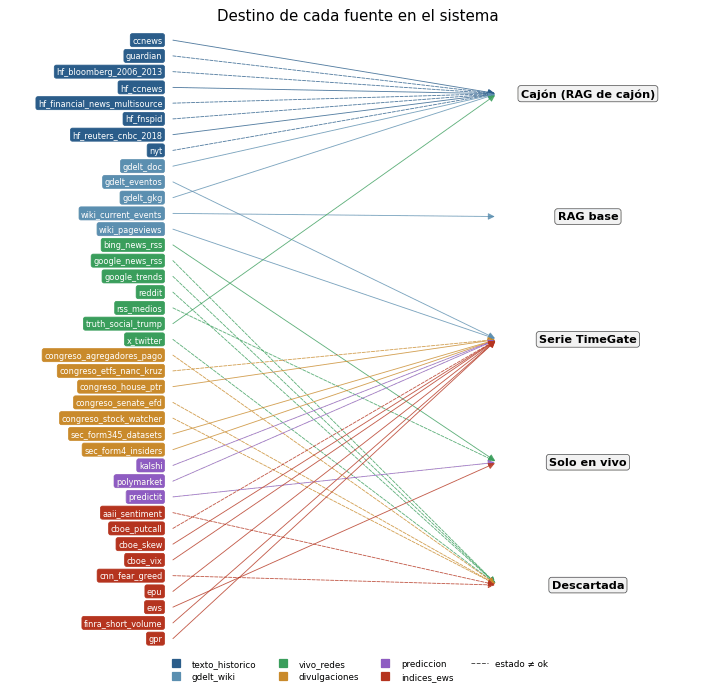

**Lectura** (cifras calculadas de las tablas):

- **serie**: 14 fuentes (gdelt_eventos, wiki_pageviews, finra_short_volume, congreso_house_ptr, congreso_etfs_nanc_kruz, sec_form4_insiders…)
- **cajon**: 11 fuentes (ccnews, hf_fnspid, hf_ccnews, hf_bloomberg_2006_2013, hf_reuters_cnbc_2018, hf_financial_news_multisource…)
- **ninguno**: 9 fuentes (google_news_rss, reddit, x_twitter, google_trends, aaii_sentiment, cnn_fear_greed…)
- **vivo**: 4 fuentes (rss_medios, bing_news_rss, predictit, ews)
- **base**: 1 fuentes (wiki_current_events)

In [4]:
fig, ax = gr.esquema_destinos(COB)
plt.show()
d = COB['destino'].fillna('ninguno').value_counts()
lectura(*[f'**{k}**: {v} fuentes ({", ".join(COB.loc[COB["destino"].fillna("ninguno") == k, "fuente"].head(6))}'
          f'{"…" if v > 6 else ""})' for k, v in d.items()])

## 1. Estado de la ejecución

Cada módulo de `sonda.MODULOS` se ejecuta en orden; uno que falla no para la sonda. El estado de cada fuente sale
del registro de peticiones (`base.estado`): **ok** si al menos el 90 % fue bien, **parcial** si no, **fallo** si
nada fue bien y **no_probada** si no se hizo ninguna petición (sin clave, de pago o bloqueada por robots.txt).
Las peticiones servidas desde la caché del corpus se registran igual, con la marca `(caché)` en el ítem.

In [5]:
display(MOD[['modulo', 'ok', 'segundos', 'n_peticiones', 'n_fichas', 'n_tablas', 'n_series', 'n_jsonl']]
        .style.hide(axis='index').format(precision=1)
        .bar(subset=['segundos'], color='#c9d9ea', vmin=0).bar(subset=['n_peticiones'], color='#e8d3b0', vmin=0))
cols = ['fuente', 'nombre', 'familia', 'tipo', 'estado_sonda', 'cobertura_inicio', 'cobertura_fin', 'destino',
        'backtest', 'agentes']
display(con_estado(RES[cols]))

modulo,ok,segundos,n_peticiones,n_fichas,n_tablas,n_series,n_jsonl
ccnews,True,22.4,12,1,3,0,1
hf_datasets,True,8.3,14,5,3,0,0
prensa_api,True,0.0,0,2,0,0,0
gdelt,True,151.7,73,3,5,1,2
wikipedia,True,0.6,36,2,4,1,1
rss,True,15.6,42,3,2,0,2
social,True,13.3,128,7,3,2,1
congreso,True,15.4,61,5,5,2,0
insiders,True,8.0,323,2,3,0,0
prediccion,True,13.3,305,3,8,5,0


fuente,nombre,familia,tipo,estado_sonda,cobertura_inicio,cobertura_fin,destino,backtest,agentes
ccnews,"Common Crawl CC-NEWS (WARC, texto completo, mundial)",texto_historico,texto,ok,2016-08-26,2026-10-14,cajon,True,"macro,equity,risk"
hf_fnspid,FNSPID (Dong et al. 2024): noticias de empresas del S&P 500,texto_historico,texto,parcial,1999-01-01,2023-12-31,cajon,True,equity
hf_ccnews,CC-NEWS limpio y deduplicado (stanford-oval/ccnews),texto_historico,texto,ok,2016-08-24,2024-06-30,cajon,True,"macro,equity,risk"
hf_bloomberg_2006_2013,Bloomberg financial news 2006-2013 (copia en HF del corpus de Ding et al. 2014),texto_historico,texto,parcial,2006-10-20,2013-11-26,cajon,True,"macro,equity,risk"
hf_reuters_cnbc_2018,"Financial news articles (Reuters/CNBC, ene-may 2018)",texto_historico,texto,ok,2018-01-01,2018-05-31,cajon,False,"macro,equity,risk"
hf_financial_news_multisource,"Financial News Multisource (24 datasets agregados, 1990-2025)",texto_historico,texto,parcial,1990-01-01,2025-11-29,cajon,True,"macro,equity,risk"
nyt,"NYT Archive API (titular, abstract y lead paragraph desde 1851)",texto_historico,titular,no_probada,1851-09-18,2026-10-14,cajon,True,"macro,equity,risk"
guardian,The Guardian Open Platform (cuerpo completo desde 1999),texto_historico,texto,no_probada,1999-01-01,2026-10-14,cajon,True,"macro,equity,risk"
gdelt_gkg,"GDELT Global Knowledge Graph 2.1 (tono, temas, entidades, titulares)",gdelt_wiki,titular,ok,2015-02-18,2026-10-14,cajon,True,"macro,risk,equity"
gdelt_eventos,GDELT Events 1.0 (1979-) y 2.0 (2015-),gdelt_wiki,evento,ok,1979-01-01,2026-10-14,serie,True,"macro,risk"


Cómo leerlo: una barra por fuente con el porcentaje de peticiones correctas (rayada si la fuente no hizo
peticiones) y el color del estado. Una fuente puede quedar `ok` con algún error suelto (FINRA pide días sin fichero
a propósito para medir la frontera).

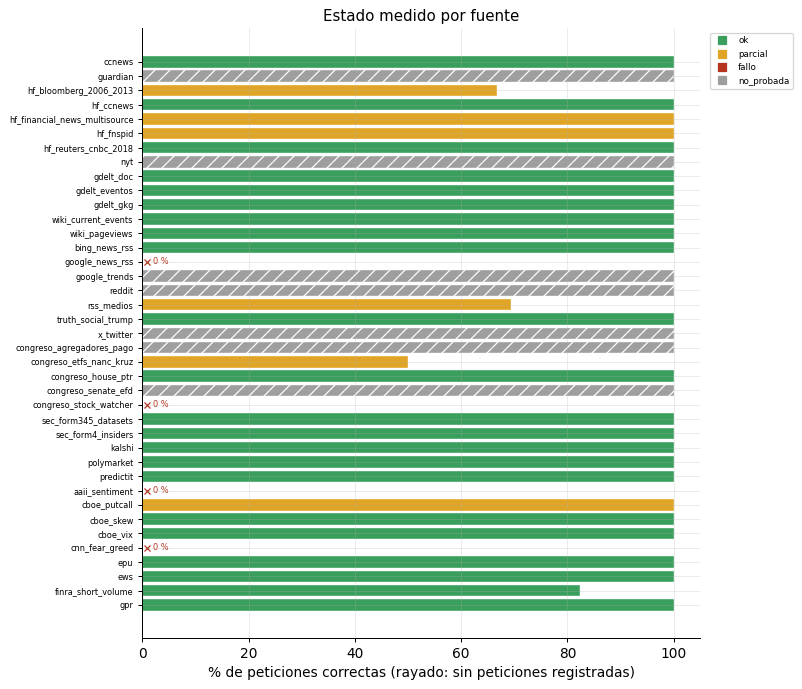

**Lectura** (cifras calculadas de las tablas):

- 12 módulos, 12 sin excepción; 278 s de ejecución (el más lento: `gdelt`, 152 s).
- 1.025 peticiones: 528 servidas desde la caché marcada y 40 fallidas.
- Fallidas por fuente: `finra_short_volume` 22, `rss_medios` 11, `congreso_stock_watcher` 2, `hf_bloomberg_2006_2013` 1, `google_news_rss` 1, `aaii_sentiment` 1, `cnn_fear_greed` 1, `congreso_etfs_nanc_kruz` 1.
- Fuentes por estado: **ok** 22, **no_probada** 7, **parcial** 6, **fallo** 4.

In [6]:
fig, ax = gr.estado_fuentes(COB, REG)
plt.show()
n_cache = int(REG['item'].astype(str).str.contains('caché').sum())
fallos = REG.loc[~REG['ok'].astype(bool), 'fuente'].value_counts()
e = RES['estado_sonda'].value_counts()
lectura(f'{len(MOD)} módulos, {int(MOD["ok"].sum())} sin excepción; {es(MOD["segundos"].sum(), 0)} s de ejecución '
        f'(el más lento: `{MOD.loc[MOD["segundos"].idxmax(), "modulo"]}`, {es(MOD["segundos"].max(), 0)} s).',
        f'{es(len(REG))} peticiones: {es(n_cache)} servidas desde la caché marcada y {es(fallos.sum())} fallidas.',
        'Fallidas por fuente: ' + ', '.join(f'`{k}` {v}' for k, v in fallos.items()) + '.',
        'Fuentes por estado: ' + ', '.join(f'**{k}** {v}' for k, v in e.items()) + '.')

## 2. Mapa de cobertura

La figura central de la sonda: desde cuándo y hasta cuándo hay datos de cada fuente, medidos (no copiados de la
documentación salvo donde la ficha lo indica).

Cómo leerlo (diagrama de Gantt): una barra por fuente desde `inicio` hasta `fin`, coloreada por **tipo de dato**
(texto completo, titular, serie, evento, instantánea). Barra tenue = no sirve para backtest (solo en vivo o
ventana demasiado corta). Rombo negro = la fuente trae hora, no solo día. Las franjas rojas son las crisis de la
Fase 1 (pista A) y las líneas punteadas, los días testigo. El eje empieza en 1979 (GDELT): las fuentes que
arrancan antes (GPR mensual en 1900, archivo de NYT en 1851) aparecen cortadas en el borde izquierdo y las
fuentes sin fechas medidas se marcan con una cruz gris.

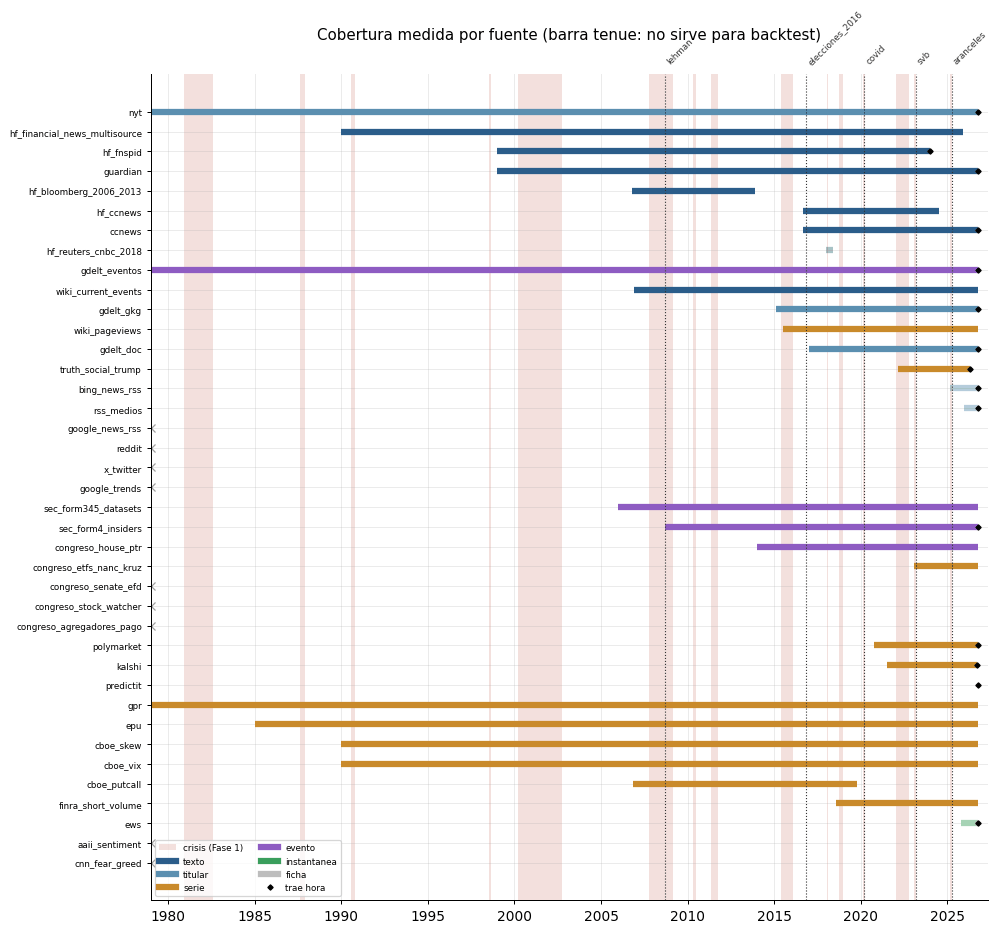

In [7]:
fig, ax = gr.gantt_cobertura(COB)
plt.show()

Cómo leerlo (mapa por épocas): cada celda dice el mejor tipo de dato que hay en la época para esa fuente: texto
completo (azul oscuro), titular (azul claro), serie o evento (ocre) o nada (gris). Es la respuesta a «qué puede
leer un agente que decide en tal año». La tabla posterior cuenta, por época, las fuentes **probadas** de cada tipo.

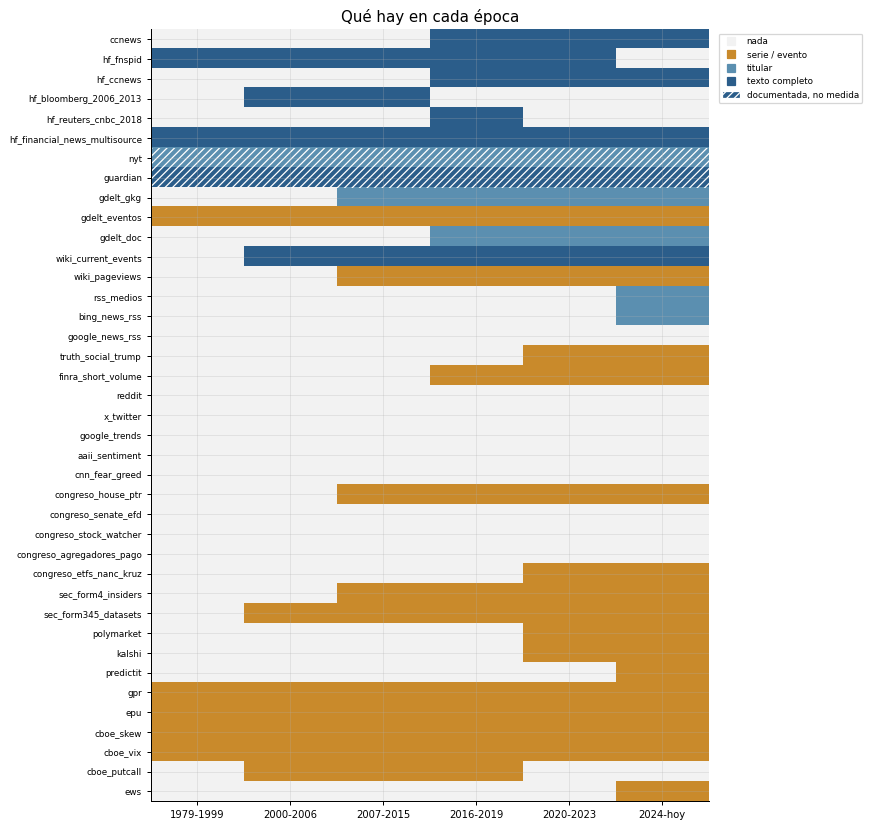

tipo,texto,titular,serie,evento,instantanea
1979-1999,2,0,4,1,0
2000-2006,4,0,5,2,0
2007-2015,4,1,6,4,0
2016-2019,6,2,7,4,0
2020-2023,5,2,10,4,0
2024-hoy,4,4,10,4,2


**Lectura** (cifras calculadas de las tablas):

- Antes de 2000 el texto completo probado se reduce a 2 fuente(s): hf_fnspid, hf_financial_news_multisource; lo demás son eventos (GDELT 1.0) e índices.
- 2007-2015: 4 fuentes de texto (hf_fnspid, hf_bloomberg_2006_2013, hf_financial_news_multisource, wiki_current_events).
- Desde 2016 entra CC-NEWS (2016-08-26): 6 fuentes de texto en 2016-2019 y 4 en 2024-hoy.
- Fuentes probadas con datos el día de Lehman: 12; en «hoy»: 9.

In [8]:
fig, ax = gr.mapa_epocas(COB)
plt.show()
EPOCAS = [('1979-1999', '1979-01-01', '1999-12-31'), ('2000-2006', '2000-01-01', '2006-12-31'),
          ('2007-2015', '2007-01-01', '2015-12-31'), ('2016-2019', '2016-01-01', '2019-12-31'),
          ('2020-2023', '2020-01-01', '2023-12-31'), ('2024-hoy', '2024-01-01', '2100-01-01')]
fin = COB['fin_dt'].fillna(pd.Timestamp.today())
filas = {}
for nombre, a, b in EPOCAS:
    m = PROBADA & (COB['inicio_dt'] <= pd.Timestamp(b)) & (fin >= pd.Timestamp(a))
    filas[nombre] = COB.loc[m, 'tipo'].value_counts()
EP = pd.DataFrame(filas).T.fillna(0).astype(int).reindex(columns=['texto', 'titular', 'serie', 'evento', 'instantanea'],
                                                          fill_value=0)
display(EP.style.background_gradient(cmap='Blues', axis=None))
txt = {n: COB.loc[PROBADA & (COB['tipo'] == 'texto') & (COB['inicio_dt'] <= pd.Timestamp(b)) & (fin >= pd.Timestamp(a)),
                  'fuente'].tolist() for n, a, b in EPOCAS}
lectura(f'Antes de 2000 el texto completo probado se reduce a {len(txt["1979-1999"])} fuente(s): '
        f'{", ".join(txt["1979-1999"]) or "ninguna"}; lo demás son eventos (GDELT 1.0) e índices.',
        f'2007-2015: {len(txt["2007-2015"])} fuentes de texto ({", ".join(txt["2007-2015"])}).',
        f'Desde 2016 entra CC-NEWS ({COB.set_index("fuente").loc["ccnews", "inicio"]}): '
        f'{len(txt["2016-2019"])} fuentes de texto en 2016-2019 y {len(txt["2024-hoy"])} en 2024-hoy.',
        f'Fuentes probadas con datos el día de Lehman: {DIAS.loc[DIAS["clave"] == "lehman", "fuentes_con_datos"].iloc[0]}; '
        f'en «hoy»: {DIAS.loc[DIAS["clave"] == "hoy", "fuentes_con_datos"].iloc[0]}.')

## 3. Texto histórico: CC-NEWS, Hugging Face, NYT y Guardian

- **CC-NEWS** (Common Crawl): WARC mensuales con el HTML completo de medios de todo el mundo desde agosto de 2016.
  La sonda lee los primeros MB de un WARC por día testigo, extrae el artículo, su idioma y la fecha del metadato
  (`article:published_time` y similares) y la compara con la de rastreo (`WARC-Date`).
- **Hugging Face**: cinco datasets de noticias financieras. Solo se leen metadatos del Hub y del *viewer* (filas,
  tamaño, licencia, fechas) y unas pocas filas; no se descarga ningún dataset.
- **NYT Archive API y Guardian Open Platform**: necesitan clave; quedan documentadas pero no probadas.

In [9]:
ART = tabla('ccnews_articulos')
CCV = tabla('ccnews_volumen')
HFD = tabla('hf_datasets')
HFA = tabla('hf_filas_anio')
HFI = tabla('hf_ccnews_idiomas')
display(CCV[['clave', 'dia', 'cobertura', 'warcs_mes', 'respuestas', 'con_texto', 'respuestas_mes_est', 'gb_mes_est',
             'mes_completo']].style.hide(axis='index').format(precision=1, na_rep='—'))

clave,dia,cobertura,warcs_mes,respuestas,con_texto,respuestas_mes_est,gb_mes_est,mes_completo
lehman,2008-09-15,False,—,—,—,—,—,—
elecciones_2016,2016-11-09,True,32.0,126.0,123.0,989408.0,23.6,True
covid,2020-03-16,True,441.0,102.0,78.0,16084152.0,473.1,True
svb,2023-03-10,True,745.0,75.0,62.0,19979410.0,799.2,True
aranceles,2025-04-07,True,491.0,70.0,54.0,12290221.0,526.7,True
hoy,2026-10-14,True,161.0,63.0,52.0,3626847.0,172.7,False


Cómo leerlo: a la izquierda, tokens por respuesta HTTP del WARC en escala log; la línea roja es el umbral a partir
del cual una respuesta cuenta como artículo (por debajo hay portadas, errores y páginas vacías). A la derecha, el
reparto por idioma de las filas de la copia limpia de Hugging Face (`stanford-oval/ccnews`).

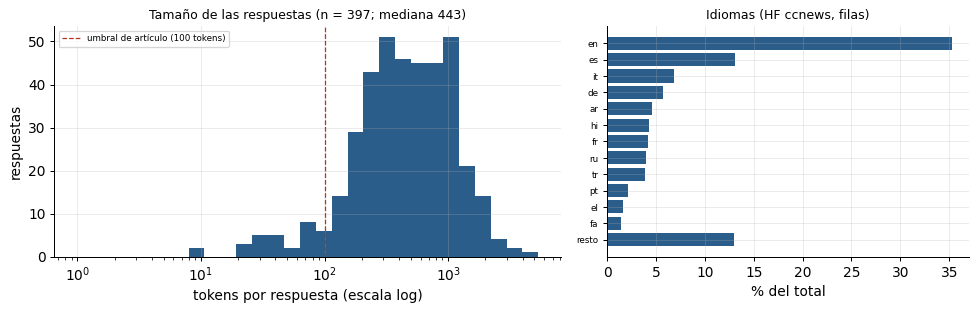

In [10]:
fig, axes = gr.ccnews_tokens_idiomas(ART, HFI)
plt.show()

Cómo leerlo: cada punto es un artículo de la muestra; eje x, la fecha que declara el propio artículo; eje y, cuándo
lo rastreó Common Crawl. Sobre la diagonal = retraso de rastreo. El color dice de dónde sale la `fecha_publicacion`
del TimeGate: `meta` (metadato del artículo, anterior al rastreo), `rastreo_sin_meta` (sin metadato: se usa la
fecha del WARC, la opción prudente) o `rastreo_meta_posterior` (metadato posterior al rastreo, imposible: se usa
el rastreo).

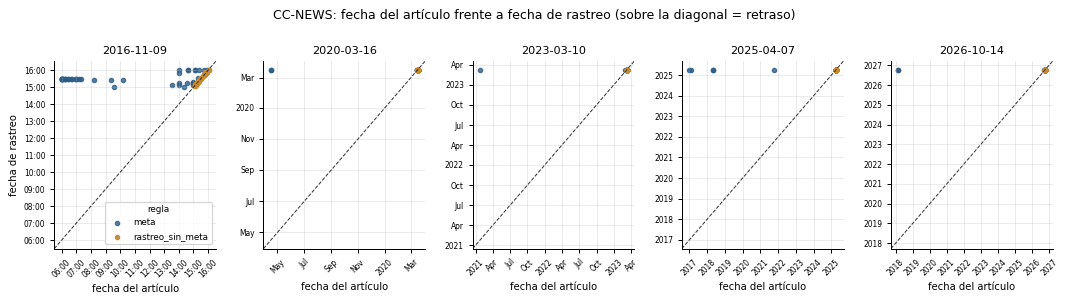

**Lectura** (cifras calculadas de las tablas):

- 436 respuestas leídas en 5 días con cobertura; 84,6 % con texto de artículo y 4,4 % duplicadas.
- Fecha del TimeGate: `meta` 55,5 %, `rastreo_sin_meta` 41,3 %, `rastreo_meta_posterior` 3,2 %.
- Retraso de rastreo con metadato: mediana 1,54 h, p90 13,3 h.
- Volumen mensual estimado: de 23,6 a 799,2 GB/mes según el día (máximo en `svb`); Lehman queda fuera (CC-NEWS empieza el 2016-08-26).

In [11]:
fig, axes = gr.fecha_articulo_vs_rastreo(ART)
plt.show()
reglas = ART['regla'].value_counts(normalize=True).mul(100)
lag = pd.to_numeric(ART.loc[ART['regla'] == 'meta', 'lag_h'], errors='coerce').dropna()
ok_cc = CCV[CCV['cobertura'].astype(bool)]
lectura(f'{es(len(ART))} respuestas leídas en {ok_cc["clave"].nunique()} días con cobertura; '
        f'{es(100 * ART["con_texto"].mean(), 1)} % con texto de artículo y {es(100 * ART["duplicado"].mean(), 1)} % duplicadas.',
        'Fecha del TimeGate: ' + ', '.join(f'`{k}` {es(v, 1)} %' for k, v in reglas.items()) + '.',
        f'Retraso de rastreo con metadato: mediana {es(lag.median(), 2)} h, p90 {es(lag.quantile(.9), 1)} h.',
        f'Volumen mensual estimado: de {es(ok_cc["gb_mes_est"].min(), 1)} a {es(ok_cc["gb_mes_est"].max(), 1)} GB/mes '
        f'según el día (máximo en `{ok_cc.loc[ok_cc["gb_mes_est"].idxmax(), "clave"]}`); Lehman queda fuera (CC-NEWS empieza el {COB.set_index("fuente").loc["ccnews", "inicio"]}).')

Cómo leerlo: filas por año de los datasets de Hugging Face que dan ese desglose (escala log). Un dataset sin barras
en un año no tiene filas medidas ese año; varios solo documentan el rango de fechas (columna `fechas` de la tabla).

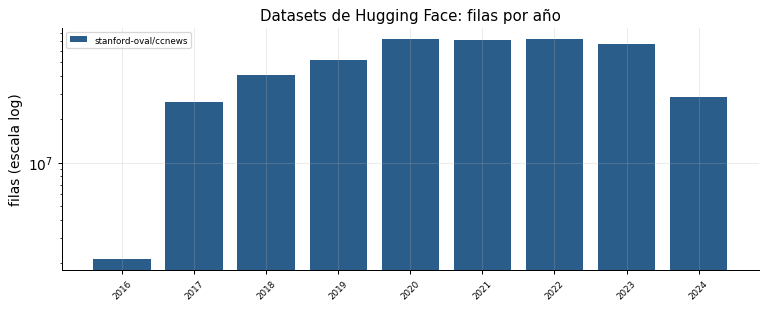

fuente,dataset,inicio,fin,fechas,filas,gb,licencia,gated,viewer,tokens_mediana
hf_fnspid,Zihan1004/FNSPID,1999-01-01,2023-12-31,documentadas,—,29.55,—,False,True,—
hf_ccnews,stanford-oval/ccnews,2016-08-24,2024-06-30,medidas (configs por año) y acotadas por la tarjeta,"893,240,667",966.82,—,False,True,346.000000
hf_bloomberg_2006_2013,KrossKinetic/Bloomberg_Financial_News,2006-10-20,2013-11-26,documentadas,—,1.39,apache-2.0,False,False,—
hf_reuters_cnbc_2018,ashraq/financial-news-articles,2018-01-01,2018-05-31,documentadas,"306,242",0.49,—,False,True,339.000000
hf_financial_news_multisource,Brianferrell787/financial-news-multisource,1990-01-01,2025-11-29,documentadas,—,21.41,other,auto,False,—


fuente,nombre,estado,inicio,tipo,licencia,nota
nyt,"NYT Archive API (titular, abstract y lead paragraph desde 1851)",no_probada,1851-09-18,titular,"NYT APIs Terms of Use: no comercial, atribución, no almacenar más de lo necesar…","sin clave (NYT_API_KEY vacía en .env): decisión del usuario, no se registra cuenta; fechas documentadas (no medidas)"
guardian,The Guardian Open Platform (cuerpo completo desde 1999),no_probada,1999-01-01,texto,Guardian Open Platform T&C,"sin clave (GUARDIAN_API_KEY vacía en .env): decisión del usuario, no se registra cuenta; fechas documentadas (no medidas)"


**Lectura** (cifras calculadas de las tablas):

- La copia limpia de CC-NEWS en Hugging Face suma 893.240.667 filas y 966,8 GB (2016-08-24 → 2024-06-30).
- El texto financiero más antiguo es `hf_financial_news_multisource` (desde 1990-01-01), con fechas documentadas.
- 3 de 5 datasets no declaran licencia en el Hub: uso solo académico y local.
- NYT y Guardian: no_probada, no_probada (sin clave por decisión del usuario).

In [12]:
fig, ax = gr.filas_anio_datasets(HFA)
plt.show()
display(HFD[['fuente', 'dataset', 'inicio', 'fin', 'fechas', 'filas', 'gb', 'licencia', 'gated', 'viewer',
             'tokens_mediana']].style.hide(axis='index').format({'filas': '{:,.0f}', 'gb': '{:.2f}'}, na_rep='—'))
PA = COB[COB['modulo'] == 'prensa_api'].merge(RES[['fuente', 'nombre', 'licencia']], on='fuente')
display(con_estado(PA[['fuente', 'nombre', 'estado', 'inicio', 'tipo', 'licencia', 'nota']], col='estado'))
hfc = HFD.set_index('fuente')
lectura(f'La copia limpia de CC-NEWS en Hugging Face suma {es(hfc.loc["hf_ccnews", "filas"])} filas y '
        f'{es(hfc.loc["hf_ccnews", "gb"], 1)} GB ({hfc.loc["hf_ccnews", "inicio"]} → {hfc.loc["hf_ccnews", "fin"]}).',
        f'El texto financiero más antiguo es `{HFD.loc[pd.to_datetime(HFD["inicio"]).idxmin(), "fuente"]}` '
        f'(desde {HFD["inicio"].min()}), con fechas {HFD.loc[pd.to_datetime(HFD["inicio"]).idxmin(), "fechas"]}.',
        f'{int(HFD["licencia"].isna().sum())} de {len(HFD)} datasets no declaran licencia en el Hub: uso solo académico y local.',
        f'NYT y Guardian: {", ".join(PA["estado"])} (sin clave por decisión del usuario).')

## 4. GDELT: GKG, eventos y DOC API

- **GKG 2.1** (desde febrero de 2015): un fichero cada 15 minutos con los artículos que GDELT ha leído, su tono,
  temas, entidades y, a veces, el titular. La sonda baja hasta 6 ficheros por día testigo (uno cada 4 h).
- **Events 1.0/2.0**: eventos codificados (CAMEO) desde 1979. Cada evento lleva `SQLDATE` (cuándo ocurrió) y
  `DATEADDED` (cuándo lo registró GDELT): para el TimeGate solo vale la segunda.
- **DOC 2.0 API**: búsqueda de titulares (desde 2017) y timeline de tono; la serie `gdelt_tono_economia` sale de
  ahí. Consultas fijas: `stock market`, `recession`, `federal reserve`.

In [13]:
GKG = tabla('gdelt_gkg_muestra')
TONO = tabla('gdelt_tono_intradia')
TEMAS = tabla('gdelt_temas')
EVL = tabla('gdelt_eventos_lag')
GDOC = tabla('gdelt_doc_muestra')
g = (GKG.dropna(subset=['fichero_utc']).groupby('clave', sort=False)
     .agg(ficheros=('fichero_utc', 'size'), articulos=('n_articulos', 'sum'), medios_por_fichero=('n_medios', 'mean'),
          tono_medio=('tono_medio', 'mean'), pct_con_titular=('pct_con_titular', 'mean'),
          pct_con_hora_medio=('pct_con_pubts', 'mean'), lag_captura_h=('lag_pub_captura_mediana_h', 'median'),
          mb_zip=('bytes_zip', lambda s: s.sum() / 1e6)))
display(g.style.format(precision=1).background_gradient(subset=['tono_medio'], cmap='RdBu', vmin=-3, vmax=3))

,ficheros,articulos,medios_por_fichero,tono_medio,pct_con_titular,pct_con_hora_medio,lag_captura_h,mb_zip
clave,,,,,,,,
elecciones_2016,6,19334.0,751.2,-0.3,0.0,36.9,2.0,77.1
covid,6,10986.0,434.5,-1.3,99.8,40.6,2.1,43.1
svb,6,7710.0,299.3,-0.6,99.8,54.6,2.8,31.6
aranceles,6,7771.0,255.0,-0.7,99.8,59.0,2.3,32.1
hoy,4,4170.0,208.2,-0.8,99.4,53.5,2.2,17.8


Cómo leerlo: a la izquierda, tono medio GKG por hora UTC en cada día testigo (negativo = lenguaje pesimista); a la
derecha, los temas económicos más citados en los días testigo, con el color del tono medio de los artículos que los
citan (rojo = más negativo).

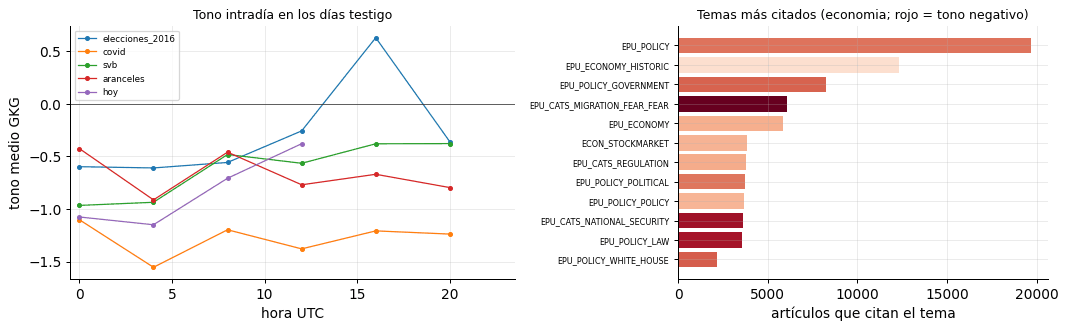

In [14]:
fig, axes = gr.gdelt_tono_temas(TONO, TEMAS, grupo='economia')
plt.show()

Cómo leerlo: días entre el hecho (`SQLDATE`) y su alta en GDELT (`DATEADDED`) por día testigo: mediana, p90 y
máximo (escala symlog, hay ceros). En la versión 2.0 la mediana es el mismo día; la cola larga son eventos
antiguos que un artículo nuevo recuerda. Lehman cae en GDELT 1.0, reprocesado en 2013: ahí el desfase es de años
y obliga a fechar por `DATEADDED`.

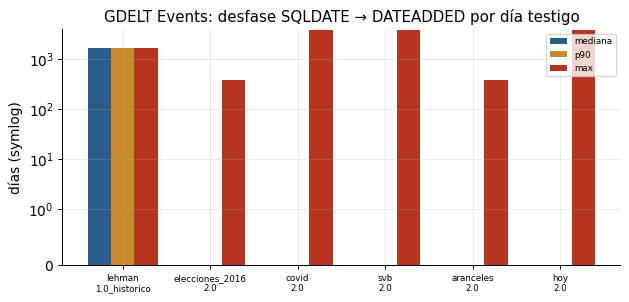

clave,version,ficheros,n,pct_sqldate_anterior,lag_dias_mediana,lag_dias_p90,lag_dias_max,pct_con_url
lehman,1.0_historico,1,47908,100.0,1602.0,1602.0,1604.0,0.0
elecciones_2016,2.0,6,15180,2.5,0.0,0.0,365.0,100.0
covid,2.0,6,9228,3.3,0.0,0.0,3650.0,100.0
svb,2.0,6,7213,3.0,0.0,0.0,3650.0,100.0
aranceles,2.0,6,7059,2.3,0.0,0.0,365.0,100.0
hoy,2.0,4,5252,2.2,0.0,0.0,3650.0,100.0


In [15]:
fig, ax = gr.gdelt_desfase_eventos(EVL)
plt.show()
display(EVL[['clave', 'version', 'ficheros', 'n', 'pct_sqldate_anterior', 'lag_dias_mediana', 'lag_dias_p90',
             'lag_dias_max', 'pct_con_url']].style.hide(axis='index').format(precision=1))

Cómo leerlo: serie diaria de tono de los artículos en inglés sobre economía (DOC API), con las crisis de la Fase 1
sombreadas. La tabla da cuántos titulares devolvió cada consulta en cada día testigo (tope de 75 por consulta).

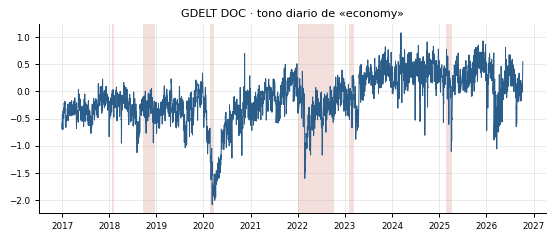

consulta,stock market,recession,federal reserve
clave,,,
lehman,—,—,—
elecciones_2016,—,—,—
covid,75,75,75
svb,75,75,75
aranceles,75,75,75
hoy,0,0,0


**Lectura** (cifras calculadas de las tablas):

- GKG: 49.971 artículos en 28 ficheros de muestra (1.785 por fichero de 15 min); 79,8 % con titular y retraso de captura mediano de 2,2 h.
- Tono GKG más negativo: `covid` (-1,28); el menos negativo: `elecciones_2016` (-0,29).
- Events 2.0: entre 2,2 % y 3,3 % de eventos con fecha del hecho anterior al día; en Lehman (1.0) el desfase mediano es de 1.602 días.
- Tono DOC: 3.533 días, 2017-01-01 → 2026-10-10; DOC API con 429 en: ningún día.

In [16]:
tono = serie('gdelt_tono_economia')
fig, axes = gr.paneles_series({'GDELT DOC · tono diario de «economy»': tono}, ncol=1, alto=2.8)
plt.show()
display(GDOC.pivot_table(index='clave', columns='consulta', values='n', aggfunc='sum', sort=False)
        .reindex([d.clave for d in dias_testigo()]).style.format(precision=0, na_rep='—'))
ev2 = EVL[EVL['version'] == '2.0']
sin_doc = GDOC.loc[GDOC['nota'].astype(str).str.startswith('fallo'), 'clave'].unique()
lectura(f'GKG: {es(g["articulos"].sum())} artículos en {int(g["ficheros"].sum())} ficheros de muestra '
        f'({es(g["articulos"].sum() / g["ficheros"].sum(), 0)} por fichero de 15 min); '
        f'{es(g["pct_con_titular"].mean(), 1)} % con titular y retraso de captura mediano de {es(g["lag_captura_h"].median(), 1)} h.',
        f'Tono GKG más negativo: `{g["tono_medio"].idxmin()}` ({es(g["tono_medio"].min(), 2)}); '
        f'el menos negativo: `{g["tono_medio"].idxmax()}` ({es(g["tono_medio"].max(), 2)}).',
        f'Events 2.0: entre {es(ev2["pct_sqldate_anterior"].min(), 1)} % y {es(ev2["pct_sqldate_anterior"].max(), 1)} % '
        f'de eventos con fecha del hecho anterior al día; en Lehman (1.0) el desfase mediano es de '
        f'{es(EVL.loc[EVL["clave"] == "lehman", "lag_dias_mediana"].iloc[0])} días.',
        f'Tono DOC: {es(len(tono))} días, {tono.index.min():%Y-%m-%d} → {tono.index.max():%Y-%m-%d}; '
        f'DOC API con 429 en: {", ".join(sin_doc) or "ningún día"}.')

## 5. Wikipedia: Current Events y visitas

- **Portal:Current events**: resumen diario de hechos mundiales con su fuente enlazada. Se lee la revisión vigente
  a las 23:59:59 UTC de cada día (lo que se sabía al cierre) y se compara con la versión actual (lo que se añadió
  después). Como la revisión de cierre es posterior a las 16:30 de Nueva York, el día D entra en la decisión de D+1.
- **Pageviews**: visitas diarias a `Recession`, `Bank_run`, `Stock_market_crash`, `Inflation`, `Financial_crisis`, `Tariff`
  desde julio de 2015 (atención del público como indicador de estrés).

In [17]:
CE = tabla('wiki_current_events')
CEI = tabla('wiki_current_events_inicio')
PICOS = tabla('wiki_pageviews_picos')
PVT = tabla('wiki_pageviews_testigo')

Cómo leerlo: a la izquierda, hechos del día al cierre (azul) frente a los de la versión actual (ocre); la diferencia
es lo que se añadió a posteriori y un agente no podía ver ese día. A la derecha, visitas diarias en escala log con
el pico de cada artículo anotado y las crisis sombreadas (máximo semanal de las visitas diarias).

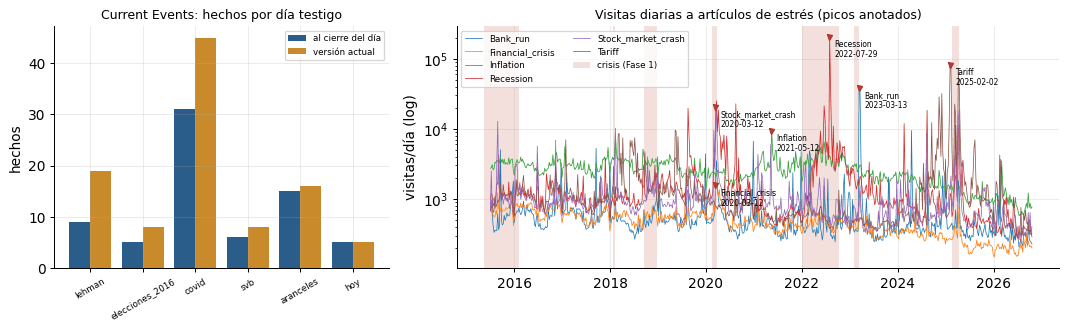

fecha,existe_hoy,revision_al_cierre,ts_creacion,lag_creacion_dias
2004-06-01,True,False,2017-09-19T20:03:00Z,4858.8
2005-06-01,True,False,2005-11-20T14:40:20Z,172.6
2006-06-01,True,False,2008-06-18T14:39:21Z,748.6
2006-12-01,True,True,2006-11-30T05:00:48Z,-0.8
2007-03-01,True,True,2007-02-28T05:00:10Z,-0.8
2007-06-01,True,True,2007-05-31T03:59:32Z,-0.8


clave,elecciones_2016,covid,svb,aranceles
articulo,,,,
Recession,2.2,22.1,0.8,18.3
Bank_run,2.0,8.2,38.5,3.7
Stock_market_crash,10.7,15.5,2.3,24.6
Inflation,1.7,1.2,0.9,1.2
Financial_crisis,1.5,3.1,1.4,3.4
Tariff,3.1,1.0,1.0,9.4


**Lectura** (cifras calculadas de las tablas):

- Current Events: 71 hechos al cierre en 6 días; la versión actual tiene un 29,7 % más, añadido después (look-ahead si se usara la actual).
- Revisión al cierre: mediana 23,62 h desde el inicio del día UTC.
- La página diaria se crea el mismo día solo desde 2006-12-01; antes se escribió meses o años después (hasta 4.859 días): no sirve para backtest anterior a esa fecha.
- Mayor salto de visitas en un día testigo: `Bank_run` en `svb` (×38,5 su mediana previa); pico absoluto: `Recession` el 2022-07-29 (202.793 visitas).

In [18]:
PV = base.leer_serie('wiki_pageviews')
PV_SEM = {s.split(':')[-1]: g.set_index(pd.to_datetime(g['fecha_referencia']))['valor'].resample('W').max()
          for s, g in PV.groupby('serie')}   # máximo semanal: conserva los picos con menos puntos
fig, axes = gr.wikipedia_hechos_visitas(CE, PV_SEM, PICOS)
plt.show()
display(CEI.style.hide(axis='index').format(precision=1))
display(PVT.pivot_table(index='articulo', columns='clave', values='ratio', sort=False)
        .style.format(precision=1).background_gradient(cmap='Reds', axis=None, vmin=0, vmax=10)
        .set_caption('Visitas del día testigo / mediana de los 90 días previos'))
anadido = 100 * (CE['n_hechos_actual'] - CE['n_hechos']).clip(lower=0).sum() / CE['n_hechos_actual'].sum()
primer = CEI.loc[CEI['revision_al_cierre'].astype(bool), 'fecha'].min()
pv = PVT.loc[PVT['ratio'].idxmax()]
lectura(f'Current Events: {int(CE["n_hechos"].sum())} hechos al cierre en {len(CE)} días; la versión actual tiene un '
        f'{es(anadido, 1)} % más, añadido después (look-ahead si se usara la actual).',
        f'Revisión al cierre: mediana {es(CE["lag_h"].median(), 2)} h desde el inicio del día UTC.',
        f'La página diaria se crea el mismo día solo desde {primer}; antes se escribió meses o años después '
        f'(hasta {es(CEI["lag_creacion_dias"].max(), 0)} días): no sirve para backtest anterior a esa fecha.',
        f'Mayor salto de visitas en un día testigo: `{pv["articulo"]}` en `{pv["clave"]}` '
        f'(×{es(pv["ratio"], 1)} su mediana previa); pico absoluto: `{PICOS.loc[PICOS["visitas_pico"].idxmax(), "articulo"]}` '
        f'el {PICOS.loc[PICOS["visitas_pico"].idxmax(), "fecha_pico"]} ({es(PICOS["visitas_pico"].max())} visitas).')

## 6. Fuentes en vivo: RSS, Bing News y Google News

Los RSS de medios y los buscadores de noticias solo dan lo publicado en las últimas horas o días: no sirven para
backtest, pero son la entrada del sistema en producción. Antes de pedir un feed se consulta su `robots.txt`;
si lo prohíbe, no se descarga (no se esquiva ningún bloqueo).

In [19]:
FEEDS = tabla('rss_feeds')
ITEMS = tabla('rss_items')

Cómo leerlo: a la izquierda, feeds por país apilados en permitidos y con datos, bloqueados por `robots.txt` y con
fallo; a la derecha, la profundidad de cada feed (horas hasta el ítem más antiguo, escala log): un feed de 24 h
solo sirve si se captura al menos una vez al día.

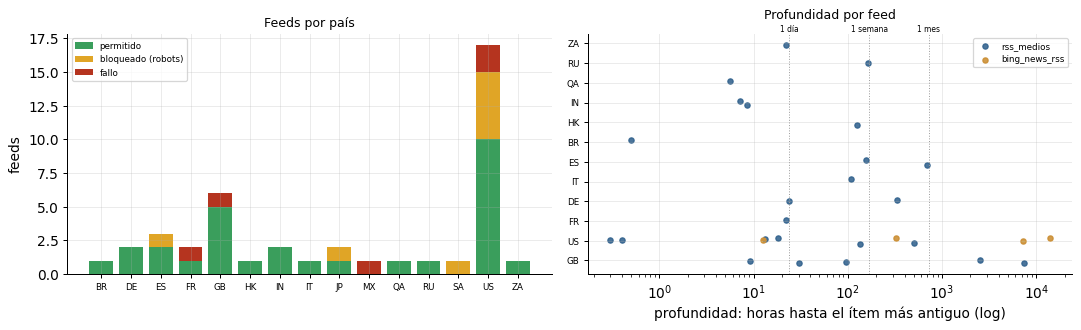

,feeds,ok,robots,items,profundidad_mediana_h,pct_con_hora,edad_min_mediana_h
fuente,,,,,,,
bing_news_rss,5,4,0,35.0,3794.5,100.0,13.6
google_news_rss,1,0,1,0.0,—,—,—
rss_medios,36,25,7,991.0,27.1,95.8,0.5


medio,pais,fecha_publicacion,titular
Nikkei Asia,JP,2026-10-14T11:27:46.421836+00:00,Central banks navigate inflation uncertainty amid supply shocks
Investing.com,US,2026-10-14T11:25:03+00:00,Why is Fluence Energy stock gaining today?
The Guardian,GB,2026-10-14T11:22:37+00:00,Diesel squeeze expected to continue into 2027 despite Trump’s deal with Russia …
Bloomberg,US,2026-10-14T11:22:03+00:00,"Bank of America Results Hit by Weaker Trading, $1.2 Billion Penalty"
Seeking Alpha,US,2026-10-14T11:21:26+00:00,National Fuel Gas to split into two publicly traded companies
InfoMoney,BR,2026-10-14T11:19:59+00:00,ASML eleva guidance pela 3ª vez em 2026 com demanda de IA puxando máquinas de c…


**Lectura** (cifras calculadas de las tablas):

- RSS de medios: 25 de 36 feeds con datos, 7 prohibidos por robots.txt; profundidad mediana 27,1 h.
- Bing News: 4 de 5 consultas con datos, 35 titulares.
- Google News: **fallo** — robots.txt de news.google.com no permite /rss/search: no se descarga.
- 1.026 ítems capturados; idiomas declarados: de, en, es, fr, it, pt.

In [20]:
fig, axes = gr.rss_feeds(FEEDS)
plt.show()
rs = (FEEDS.groupby('fuente')
      .agg(feeds=('feed', 'size'), ok=('estado', lambda s: int((s == 'ok').sum())),
           robots=('robots_ok', lambda s: int((~s.astype(bool)).sum())),
           items=('n_items', 'sum'), profundidad_mediana_h=('profundidad_h', 'median'),
           pct_con_hora=('pct_con_hora', 'mean'), edad_min_mediana_h=('edad_min_h', 'median')))
display(rs.style.format(precision=1, na_rep='—'))
muestra = (ITEMS.dropna(subset=['titular']).sort_values('fecha_publicacion', ascending=False)
           .drop_duplicates('medio').head(6)[['medio', 'pais', 'fecha_publicacion', 'titular']])
display(muestra.assign(titular=muestra['titular'].map(lambda t: corto(t, 80))).style.hide(axis='index')
        .set_caption('Titulares más recientes por medio (cortos, solo metadatos)'))
gn = COB.set_index('fuente').loc['google_news_rss']
lectura(f'RSS de medios: {rs.loc["rss_medios", "ok"]} de {rs.loc["rss_medios", "feeds"]} feeds con datos, '
        f'{rs.loc["rss_medios", "robots"]} prohibidos por robots.txt; profundidad mediana {es(rs.loc["rss_medios", "profundidad_mediana_h"], 1)} h.',
        f'Bing News: {rs.loc["bing_news_rss", "ok"]} de {rs.loc["bing_news_rss", "feeds"]} consultas con datos, '
        f'{int(rs.loc["bing_news_rss", "items"])} titulares.',
        f'Google News: **{gn["estado"]}** — {gn["nota"]}',
        f'{es(len(ITEMS))} ítems capturados; idiomas declarados: {", ".join(sorted(ITEMS["idioma"].dropna().unique()))}.')

## 7. Limpieza: duplicados, idiomas y sindicación

`limpieza.py` junta los titulares de todas las fuentes de texto por día testigo y aplica tres filtros en cascada:
URL normalizada, similitud de Jaccard de titulares y simhash del texto. GKG entra con una muestra fija de 500
documentos por día (ordenados por `doc_id`) porque el embudo es cuadrático. La **sindicación** (la misma nota de
agencia publicada por varios medios) se detecta con el filtro de titulares y se guarda con el medio original.

In [21]:
EMB = tabla('limpieza_embudo')
IDI = tabla('limpieza_idiomas')
SIN = tabla('limpieza_sindicacion')

Cómo leerlo: un panel por día testigo; cada barra es el número de documentos que quedan tras cada etapa (y el % del
bruto). Si una etapa no recorta nada, ese filtro no aporta en esos datos.

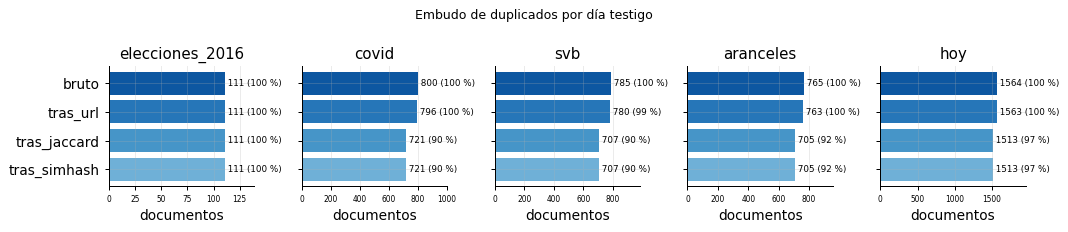

In [22]:
dias = list(dict.fromkeys(EMB['dia']))
fig, axes = plt.subplots(1, len(dias), figsize=(12, 2.6))
for k, (ax, d) in enumerate(zip(np.atleast_1d(axes), dias)):
    gr.embudo_duplicados(EMB[EMB['dia'] == d], ax=ax, titulo=d)
    ax.tick_params(axis='x', labelsize=6)
    if k:
        ax.set_yticklabels([])
fig.suptitle('Embudo de duplicados por día testigo', fontsize=10)
fig.tight_layout()
plt.show()

Cómo leerlo: reparto por idioma de cada fuente (porcentaje de documentos). GDELT y Bing se piden en inglés; CC-NEWS
y los RSS son multilingües.

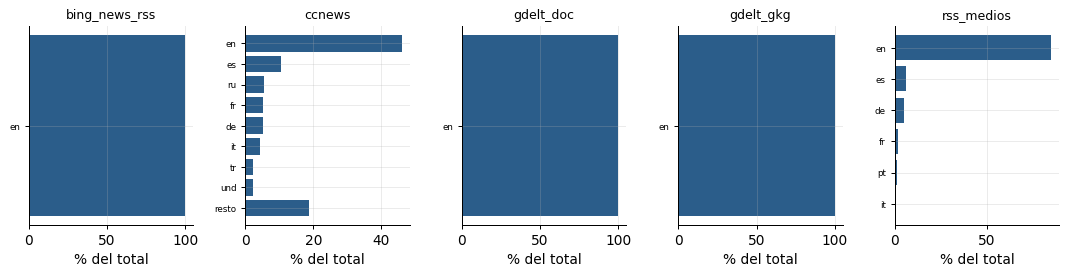

dia,fuente,titular,n_medios,medio_original
covid,gdelt_doc,Bank of Japan holds emergency policy meeting after Fed cut,10,abcnews.go.com
svb,gdelt_doc,More Than $70 Billion Wiped Off Crypto Market in 24 Hours as Bitcoin Drops 8 % …,8,nbcwashington.com
aranceles,gdelt_doc,Tariffs : The potential positive impact on your finances,8,wcpo.com
aranceles,gdelt_doc,Trump Breaks Silence On Sweeping Tariff Plans Following Market Downturn,8,newsradio1290wtks.iheart.com
covid,gdelt_doc,Business and economic reports scheduled for Tuesday,7,abcnews.go.com
aranceles,gdelt_doc,Trump digs in his heels as global markets keep dropping over tariffs,7,wsbradio.com
svb,gdelt_doc,UK Economy Rebounds With Stronger - Than - Expected January GDP Print,6,nbcphiladelphia.com
aranceles,gdelt_doc,Worst stock market days in history,5,fox29.com


**Lectura** (cifras calculadas de las tablas):

- Documentos que quedan tras el embudo: `elecciones_2016` 100,0 %, `covid` 90,1 %, `svb` 90,1 %, `aranceles` 92,2 %, `hoy` 96,7 %.
- Eliminados por etapa (todos los días): URL 12, Jaccard 256, simhash 0 (casi todo son titulares sin cuerpo, así que el simhash no actúa).
- 67 grupos de sindicación; el mayor reúne 10 medios (`covid`, origen abcnews.go.com).
- CC-NEWS: 31 idiomas, 46,0 % en inglés.

In [23]:
fuentes_idi = list(dict.fromkeys(IDI['fuente']))
fig, axes = plt.subplots(1, len(fuentes_idi), figsize=(12, 3.2))
for ax, f in zip(np.atleast_1d(axes), fuentes_idi):
    gr.barras_idiomas(IDI[IDI['fuente'] == f], peso='n', top=8, titulo=f, ax=ax)
fig.tight_layout()
plt.show()
top = SIN.sort_values('n_medios', ascending=False).head(8)
display(top.assign(titular=top['titular'].map(lambda t: corto(t, 80)))
        [['dia', 'fuente', 'titular', 'n_medios', 'medio_original']].style.hide(axis='index')
        .set_caption('Titulares más sindicados (titular recortado)'))
fin_e = EMB[EMB['etapa'] == 'tras_simhash'].set_index('dia')
paso = EMB.groupby('etapa')['eliminados'].sum()
lectura('Documentos que quedan tras el embudo: ' + ', '.join(f'`{d}` {es(r.pct_restante, 1)} %' for d, r in fin_e.iterrows()) + '.',
        f'Eliminados por etapa (todos los días): URL {int(paso.get("tras_url", 0))}, Jaccard {int(paso.get("tras_jaccard", 0))}, '
        f'simhash {int(paso.get("tras_simhash", 0))} (casi todo son titulares sin cuerpo, así que el simhash no actúa).',
        f'{len(SIN)} grupos de sindicación; el mayor reúne {int(SIN["n_medios"].max())} medios '
        f'(`{SIN.loc[SIN["n_medios"].idxmax(), "dia"]}`, origen {SIN.loc[SIN["n_medios"].idxmax(), "medio_original"]}).',
        f'CC-NEWS: {IDI[IDI["fuente"] == "ccnews"]["idioma"].nunique()} idiomas, '
        f'{es(IDI[(IDI["fuente"] == "ccnews") & (IDI["idioma"] == "en")]["pct_fuente"].sum(), 1)} % en inglés.')

## 8. Congreso: operaciones de los representantes (STOCK Act)

Los miembros de la Cámara presentan un *Periodic Transaction Report* (PTR) por cada operación, con un plazo legal de
45 días. El índice anual del House Clerk da todos los PTR desde 2014; la sonda lee una muestra de PDF electrónicos
y extrae las operaciones. Para el TimeGate la fecha es la de **publicación** (`FilingDate` + 1 día hábil, medido
con `Last-Modified` del PDF), nunca la de la operación. El Senado (eFD) exige aceptar condiciones de uso por
sesión y no se automatiza. En las tablas no se muestran nombres de personas.

In [24]:
PTRA = tabla('congreso_ptr_anio')
PTRM = tabla('congreso_ptr_mes')
OPS = tabla('congreso_operaciones')
ETF = tabla('congreso_etf_resumen')

Cómo leerlo: a la izquierda, PTR por año separados en electrónicos (texto legible) y escaneados (PDF imagen, que
necesitan OCR); a la derecha, días entre la operación y su publicación, con el plazo legal en rojo.

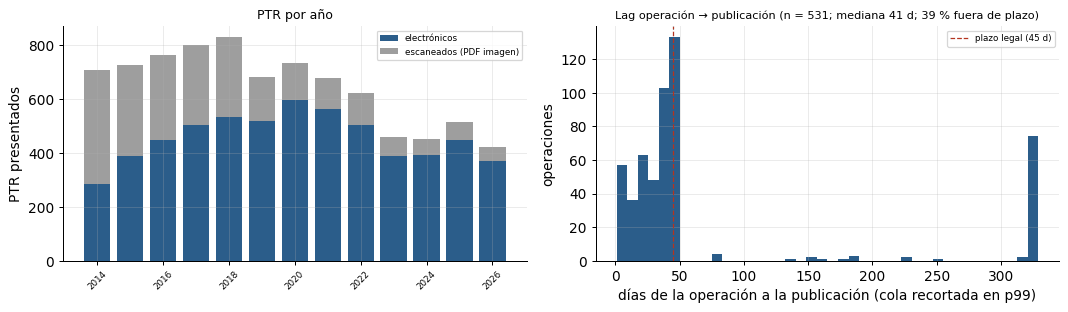

In [25]:
fig, axes = gr.congreso_ptr(PTRA, OPS)
plt.show()

Cómo leerlo: PTR presentados por mes (la serie `congreso_ptr_diarios` agregada) y cierre del ETF NANC, que replica
las carteras declaradas por congresistas demócratas (KRUZ, la réplica republicana, no devolvió precios).

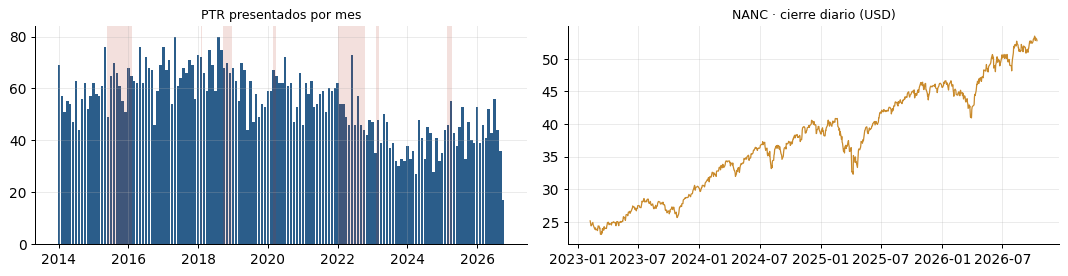

ticker,inicio,fin,dias,rent_total_pct
NANC,2023-02-07,2026-10-13,924,110.0
KRUZ,—,—,0,—


clase,CS,GS,OP,OT,PS,ST,VA
tipo,,,,,,,
canje,0,0,0,0,0,2,2
compra,5,25,4,1,2,175,0
venta,4,18,5,2,0,227,0
venta parcial,0,1,0,0,0,54,0


**Lectura** (cifras calculadas de las tablas):

- 8.399 PTR entre 2014 y 2026; electrónicos: 40,3 % en 2014 y 87,2 % en 2025.
- 531 operaciones extraídas de la muestra, 88,9 % con ticker.
- Operación → publicación: mediana 41 días, p90 329; 38,6 % supera el plazo legal de 45 días.
- NANC: 2023-02-07 → 2026-10-13 (el proxy no cubre nada anterior); KRUZ: 0 días con precio.

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
m = PTRM.assign(mes=pd.to_datetime(PTRM['mes']))
axes[0].bar(m['mes'], m['n_ptr'], width=25, color=gr.C_BASE)
gr.sombrear_crisis(axes[0], desde=m['mes'].min())
axes[0].set_title('PTR presentados por mes', fontsize=10)
nanc = serie('congreso_etf_nanc_kruz', 'nanc_cierre')
axes[1].plot(nanc.index, nanc.values, color=gr.C_FAMILIA['divulgaciones'], lw=1)
axes[1].set_title('NANC · cierre diario (USD)', fontsize=10)
fig.tight_layout()
plt.show()
display(ETF.style.hide(axis='index').format(precision=1, na_rep='—'))
display(OPS.groupby(['tipo', 'clase']).size().unstack(fill_value=0).style.background_gradient(cmap='Blues', axis=None)
        .set_caption('Operaciones extraídas por tipo y clase de activo (ST acción, GS deuda pública, OP opción, CS bono)'))
lag = pd.to_numeric(OPS['lag_dias'], errors='coerce').dropna()
ult = PTRA.sort_values('anio').iloc[-2]
lectura(f'{es(PTRA["n_ptr"].sum())} PTR entre {int(PTRA["anio"].min())} y {int(PTRA["anio"].max())}; '
        f'electrónicos: {es(PTRA["pct_electronicos"].iloc[0], 1)} % en {int(PTRA["anio"].iloc[0])} y '
        f'{es(ult["pct_electronicos"], 1)} % en {int(ult["anio"])}.',
        f'{es(len(OPS))} operaciones extraídas de la muestra, {es(100 * OPS["ticker"].notna().mean(), 1)} % con ticker.',
        f'Operación → publicación: mediana {es(lag.median())} días, p90 {es(lag.quantile(.9))}; '
        f'{es(100 * (lag > 45).mean(), 1)} % supera el plazo legal de 45 días.',
        f'NANC: {ETF.loc[ETF["ticker"] == "NANC", "inicio"].iloc[0]} → {ETF.loc[ETF["ticker"] == "NANC", "fin"].iloc[0]} '
        f'(el proxy no cubre nada anterior); KRUZ: {int(ETF.loc[ETF["ticker"] == "KRUZ", "dias"].iloc[0])} días con precio.')

## 9. Insiders: SEC Form 4

Directivos y grandes accionistas declaran sus operaciones en el Form 4 (plazo legal: 2 días hábiles desde 2002).
La sonda lee el índice diario de EDGAR en los días testigo y los tres siguientes, y una muestra de XML (testigo y
búsqueda de compras `P`). La `fecha_publicacion` sale de la hora de aceptación de la SEC: antes de las 16:00 de
Nueva York vale ese día; si no, el día hábil siguiente.

In [27]:
INS = tabla('insiders_operaciones')
INF = tabla('insiders_form4')
INI = tabla('insiders_indice')

Cómo leerlo: a la izquierda, días entre la transacción y su publicación (en rojo, el plazo legal, y sombreado, el
mismo plazo cuando cae un fin de semana); a la derecha, los códigos de transacción (P compra en mercado, S venta,
A concesión, M ejercicio de opciones…). Las compras `P` son la señal que interesa y están sobrerrepresentadas
porque la muestra las busca.

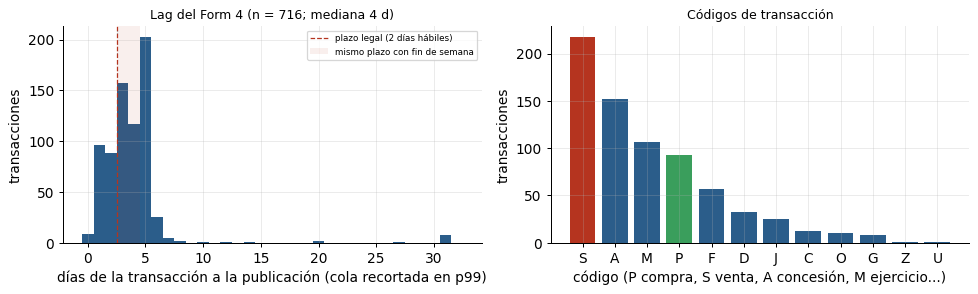

,dias,form4_dia,form4a_dia,mb_indice
dia_testigo,,,,
lehman,4,1344.0,52.2,1.8
elecciones_2016,3,1836.3,32.7,2.6
covid,4,2308.5,50.8,2.8
svb,4,2133.2,53.0,3.1
aranceles,4,746.8,27.0,2.9
hoy,1,1045.0,22.0,0.9


**Lectura** (cifras calculadas de las tablas):

- 1.634 Form 4 por día hábil de media en los índices leídos.
- 302 formularios leídos (63 con compra P) → 716 transacciones.
- Transacción → publicación: mediana 4 días, p90 5; 34,8 % tarda más de 4 días naturales.
- 65,9 % de los formularios se aceptó tras el cierre y pasa al día hábil siguiente.

In [28]:
fig, axes = gr.form4_lag_codigos(INS)
plt.show()
idx = (INI[INI['n_form4'] > 0].groupby('dia_testigo', sort=False)
       .agg(dias=('dia', 'size'), form4_dia=('n_form4', 'mean'), form4a_dia=('n_form4a', 'mean'),
            mb_indice=('bytes', lambda s: s.sum() / 1e6)))
display(idx.style.format(precision=1).bar(subset=['form4_dia'], color='#e8d3b0', vmin=0))
lag = pd.to_numeric(INS['lag_dias'], errors='coerce').dropna()
tras = (pd.to_datetime(INF['fecha_publicacion']) > pd.to_datetime(INF['fecha_presentacion'])).mean()
lectura(f'{es(INI["n_form4"].sum() / (INI["n_form4"] > 0).sum(), 0)} Form 4 por día hábil de media en los índices leídos.',
        f'{es(len(INF))} formularios leídos ({int(INF["compra_p"].astype(bool).sum())} con compra P) → {es(len(INS))} transacciones.',
        f'Transacción → publicación: mediana {es(lag.median())} días, p90 {es(lag.quantile(.9))}; '
        f'{es(100 * (lag > 4).mean(), 1)} % tarda más de 4 días naturales.',
        f'{es(100 * tras, 1)} % de los formularios se aceptó tras el cierre y pasa al día hábil siguiente.')

## 10. Mercados de predicción: Polymarket, Kalshi y PredictIt

Probabilidades implícitas de eventos (recesión, decisiones de la Fed…) que cotizan en tiempo real. Polymarket da
historial diario desde finales de 2022 (antes, el AMM no guarda historial); Kalshi, velas diarias de sus series
macro desde 2021; PredictIt, solo la instantánea actual. Para el TimeGate se toma el último precio anterior a las
16:30 de Nueva York de cada día.

In [29]:
PML = tabla('polymarket_liquidez_anio')
KAL = tabla('kalshi_liquidez_anio')
EMBL = tabla('polymarket_emblematicos')
SAL = tabla('polymarket_saltos')
PDT = tabla('prediccion_dias_testigo')
PIT = tabla('predictit_instantanea')

Cómo leerlo: volumen negociado por año en escala log (Polymarket en USD; Kalshi en contratos). Una barra rayada
indica que la muestra llegó al techo de mercados por año y el volumen real es mayor.

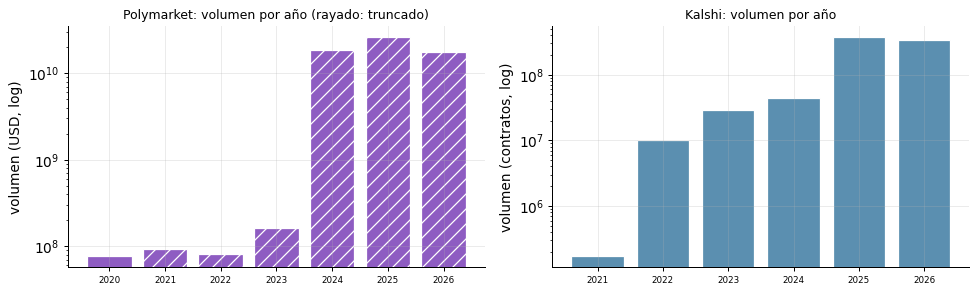

In [30]:
fig, axes = gr.prediccion_liquidez(PML, KAL)
plt.show()

Cómo leerlo: probabilidad diaria del «Yes» en dos mercados emblemáticos, con los saltos de 15 puntos o más
marcados (triángulo verde = sube, rojo = baja). Los saltos coinciden con noticias concretas: son candidatos a evento
para la validez.

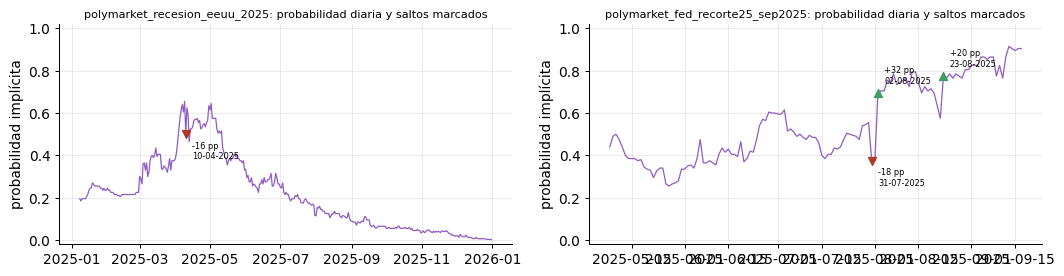

serie,pregunta,inicio,fin,n_dias,volumen_usd,cerrado,resultado,p_min,p_max,n_saltos_15pp
polymarket_recesion_eeuu_2025,US recession in 2025?,2025-01-08,2025-12-31,358,"11,734,512",True,0,0.003,0.655,1
polymarket_fed_recorte25_sep2025,Fed decreases interest rates by 25 bps after September 2025 meeting?,2025-05-08,2025-09-17,133,"36,329,926",True,1,0.255,0.915,3
polymarket_recesion_eeuu_2026,US recession by end of 2026?,2025-09-30,2026-10-14,380,"2,300,416",False,—,0.065,0.460,0
polymarket_recesion_eeuu_2024,U.S. Recession in 2024?,2024-08-05,2024-12-31,149,"875,848",True,0,0.004,0.295,1
polymarket_fed_sin_recortes_2026,Will no Fed rate cuts happen in 2026?,2025-09-30,2026-10-14,380,"8,906,435",False,—,0.017,0.970,0


plataforma,polymarket,kalshi
dia,,
lehman,0,0
elecciones_2016,0,0
covid,0,0
svb,"43,995,130","25,726,347"
aranceles,"8,351,043,941","90,260,258"
hoy,"6,673,465,584","26,874,729"


**Lectura** (cifras calculadas de las tablas):

- Polymarket: máximo volumen en 2025 (26,0 mil millones USD en la muestra; 6 años truncados por el techo).
- Kalshi: de 171.282 contratos en 2021 a 373.135.116 en 2025.
- Días testigo con mercados líquidos: svb, aranceles, hoy; ningún día testigo anterior al 2023-03-10 tiene mercados activos: no cubren las crisis históricas.
- 5 saltos ≥ 15 pp en 5 mercados emblemáticos; PredictIt: 203 mercados y 608 contratos en la instantánea.

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, nombre in zip(axes, ['polymarket_recesion_eeuu_2025', 'polymarket_fed_recorte25_sep2025']):
    gr.serie_con_saltos(base.leer_serie(nombre), SAL, nombre=nombre, ax=ax)
    ax.title.set_fontsize(9)
fig.tight_layout()
plt.show()
display(EMBL[['serie', 'pregunta', 'inicio', 'fin', 'n_dias', 'volumen_usd', 'cerrado', 'resultado', 'p_min', 'p_max',
              'n_saltos_15pp']].style.hide(axis='index').format({'volumen_usd': '{:,.0f}', 'p_min': '{:.3f}',
                                                                 'p_max': '{:.3f}', 'resultado': '{:.0f}'}, na_rep='—'))
display(PDT[['plataforma', 'dia', 'n_activos', 'volumen_usd', 'cobertura']].pivot_table(
    index='dia', columns='plataforma', values='volumen_usd', sort=False).style.format('{:,.0f}')
    .set_caption('Volumen (USD) de los mercados activos cada día testigo (Polymarket: los 50 mayores)'))
anio_liq = PML.loc[PML['volumen_usd'].idxmax()]
primera_liq = pd.to_datetime(PDT.loc[PDT['cobertura'] == 'ok', 'fecha']).min()
lectura(f'Polymarket: máximo volumen en {int(anio_liq["anio"])} ({es(anio_liq["volumen_usd"] / 1e9, 1)} mil millones USD '
        f'en la muestra; {int(PML["truncado"].astype(bool).sum())} años truncados por el techo).',
        f'Kalshi: de {es(KAL["volumen_contratos"].iloc[0])} contratos en {int(KAL["anio"].iloc[0])} a '
        f'{es(KAL["volumen_contratos"].max())} en {int(KAL.loc[KAL["volumen_contratos"].idxmax(), "anio"])}.',
        f'Días testigo con mercados líquidos: {", ".join(PDT.loc[PDT["cobertura"] == "ok", "dia"].unique())}; '
        f'ningún día testigo anterior al {primera_liq:%Y-%m-%d} tiene mercados activos: no cubren las crisis históricas.',
        f'{len(SAL)} saltos ≥ 15 pp en {EMBL["serie"].nunique()} mercados emblemáticos; PredictIt: '
        f'{int(PIT["n_mercados"].iloc[0])} mercados y {int(PIT["n_contratos"].iloc[0])} contratos en la instantánea.')

## 11. Índices alternativos: GPR, EPU, CBOE y FINRA

Índices construidos a partir de noticias (riesgo geopolítico GPR de Caldara e Iacoviello; incertidumbre de
política económica EPU de Baker, Bloom y Davis) y de mercado (VIX, SKEW y ratios put/call de CBOE; volumen en corto
de FINRA). Todos van a serie TimeGate con su regla de publicación. GPR y EPU se guardan con el vintage actual
(`vintage_actual_revisable`): la fecha de publicación es correcta, pero el valor puede haberse revisado después; los
vintages de GPR desde 2022 permiten medir esa revisión.

In [32]:
IR = tabla('indices_resumen')
IT = tabla('indices_testigo')
GPRV = tabla('gpr_vintages_testigo')
PCD = tabla('cboe_putcall_diario')

Cómo leerlo: pequeños múltiplos de cada índice con las crisis de la Fase 1 sombreadas y los días testigo punteados.
Las series diarias largas se dibujan como media mensual. GPR y EPU diarios en escala log. El put/call acaba en
2019: los CSV históricos de CBOE están congelados y el JSON diario posterior no tiene solape para validar el empalme.

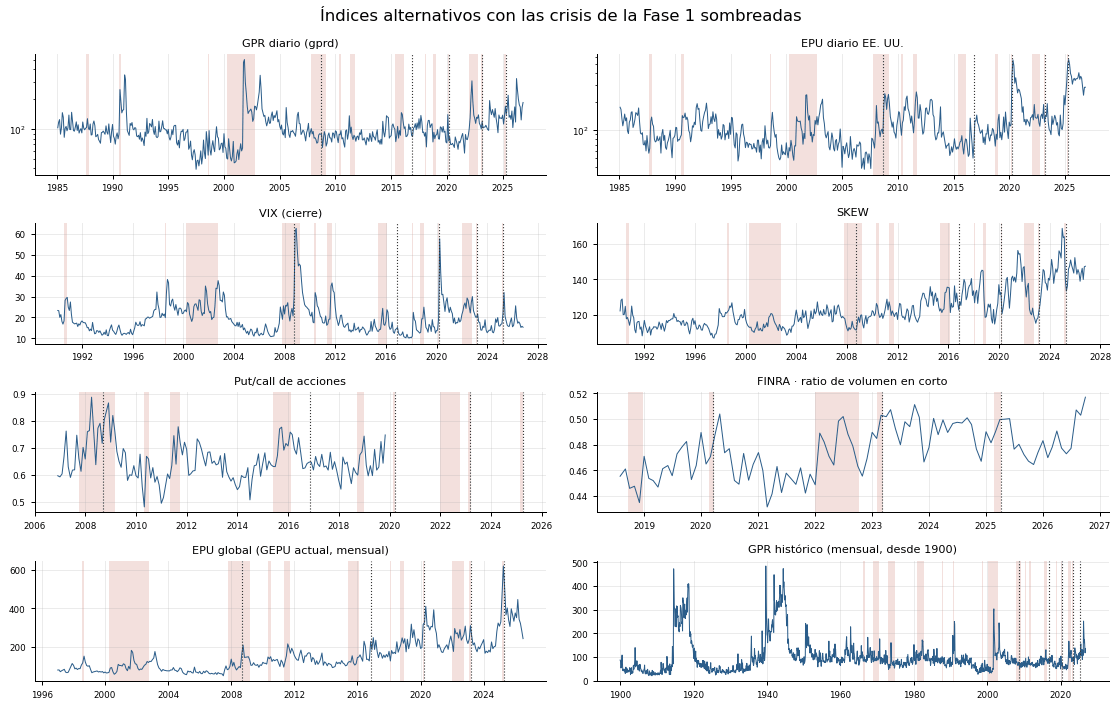

In [33]:
PANEL = {
    'GPR diario (gprd)': serie('gpr_diario', 'gprd'),
    'EPU diario EE. UU.': serie('epu_diario_usa', 'epu_usa_diario'),
    'VIX (cierre)': serie('cboe_vix', 'vix_cierre'),
    'SKEW': serie('cboe_skew', 'skew'),
    'Put/call de acciones': serie('cboe_putcall_equity', 'pc_equity_ratio'),
    'FINRA · ratio de volumen en corto': serie('finra_short_ratio_mercado'),
    'EPU global (GEPU actual, mensual)': serie('epu_global_mensual', 'gepu_current'),
    'GPR histórico (mensual, desde 1900)': serie('gpr_mensual', 'gprh'),
}
# Las series diarias largas se dibujan como media mensual: la figura pesa menos y las crisis se siguen viendo
PANEL_FIG = {k: (v.resample('ME').mean() if len(v) > 2500 else v) for k, v in PANEL.items()}
fig, axes = gr.indices_paneles(PANEL_FIG, ncol=2, log=['GPR diario (gprd)', 'EPU diario EE. UU.'], max_puntos=None)
plt.show()

Cómo leerlo: percentil causal (calculado solo con datos anteriores) del valor que veía un agente cada día testigo.
Rojo = valor extremo respecto a su propia historia hasta ese día.

In [34]:
sel = ['gprd', 'epu_usa_diario', 'vix_cierre', 'skew', 'pc_equity_ratio', 'pc_total_ratio', 'gepu_current', 'gpr']
P = IT[IT['serie'].isin(sel)].pivot_table(index='serie', columns='dia', values='percentil_causal', sort=False)
P = P.reindex(index=[s for s in sel if s in P.index], columns=[d.clave for d in dias_testigo() if d.clave in P.columns])
display(P.style.format(precision=1, na_rep='—').background_gradient(cmap='Reds', axis=None, vmin=0, vmax=100)
        .set_caption('Percentil causal en cada día testigo'))
display(IR.groupby('fichero', sort=False).agg(series=('serie', 'size'), inicio=('inicio', 'min'), fin=('fin', 'max'),
                                              n=('n', 'max'), metodo=('metodo', 'first'),
                                              lag_regla_dias=('lag_mediano_regla_dias', 'first')))
display(GPRV.dropna(subset=['vintage'])[['dia', 'tipo', 'vintage', 'lag_dias', 'valor_vintage', 'valor_hoy', 'revision_pct']]
        .style.hide(axis='index').format(precision=2).set_caption('GPR: valor en el vintage de la época frente al de hoy'))
covid = IT[IT['dia'] == 'covid'].groupby('serie')['percentil_causal'].first()
lectura(f'COVID: percentil causal {es(covid.get("vix_cierre"), 1)} en el VIX, {es(covid.get("epu_usa_diario"), 1)} en el EPU '
        f'diario y {es(covid.get("gprd"), 1)} en el GPR diario.',
        f'Revisión de GPR entre el vintage de la época y hoy: de {es(GPRV["revision_pct"].min(), 1)} % a '
        f'{es(GPRV["revision_pct"].max(), 1)} % en los días testigo con vintage.',
        f'Put/call: los CSV acaban el {IR.loc[IR["fichero"] == "cboe_putcall_total", "fin"].max()}; el JSON diario empieza el '
        f'{PCD.loc[PCD["dia"] == "inicio_json", "fecha"].iloc[0]} (sin solape para validar).',
        f'FINRA: {es(len(PANEL["FINRA · ratio de volumen en corto"]))} días con fichero muestreados; '
        f'ratio medio {es(PANEL["FINRA · ratio de volumen en corto"].mean(), 3)}.')

dia,lehman,elecciones_2016,covid,svb,aranceles,hoy
serie,,,,,,
gprd,36.7,28.8,1.9,19.0,71.2,73.9
epu_usa_diario,65.3,70.6,99.8,56.9,100.0,88.4
vix_cierre,85.1,54.7,99.6,72.8,98.8,33.8
skew,10.4,97.9,92.3,65.7,88.4,98.2
pc_equity_ratio,94.7,68.8,57.3,57.3,57.3,57.3
pc_total_ratio,58.4,99.4,77.9,77.9,77.9,77.9
gepu_current,65.9,81.4,96.4,91.0,97.3,86.8
gpr,43.7,40.8,19.7,84.3,96.7,89.8


,series,inicio,fin,n,metodo,lag_regla_dias
fichero,,,,,,
gpr_diario,4,1985-01-01,2026-10-13,15261,vintage_actual_revisable,4.0
gpr_mensual,12,1900-01-01,2026-09-01,1521,vintage_actual_revisable,31.0
epu_diario_usa,1,1985-01-01,2026-10-13,15261,vintage_actual_revisable,1.0
epu_global_mensual,2,1997-01-01,2026-07-01,355,vintage_actual_revisable,91.0
cboe_skew,1,1990-01-02,2026-10-13,9247,fichero_tras_cierre,1.0
cboe_vix,2,1990-01-02,2026-10-13,9293,fichero_tras_cierre,1.0
cboe_putcall_total,3,2006-11-01,2019-10-04,3253,fichero_tras_cierre,1.0
cboe_putcall_equity,3,2006-11-01,2019-10-04,3253,fichero_tras_cierre,1.0
cboe_putcall_index,3,2006-11-01,2019-10-04,3253,fichero_tras_cierre,1.0


dia,tipo,vintage,lag_dias,valor_vintage,valor_hoy,revision_pct
svb,diario,data_gpr_daily_recent_20230313.xls,3.00,98.05,113.44,15.70
svb,mensual,data_gpr_export_202304.xls,0.00,105.69,105.38,-0.29
aranceles,diario,data_gpr_daily_recent_20250407.xls,0.00,150.93,125.71,-16.71
aranceles,mensual,data_gpr_export_202505.xls,0.00,136.52,141.19,3.42


**Lectura** (cifras calculadas de las tablas):

- COVID: percentil causal 99,6 en el VIX, 99,8 en el EPU diario y 1,9 en el GPR diario.
- Revisión de GPR entre el vintage de la época y hoy: de -16,7 % a 15,7 % en los días testigo con vintage.
- Put/call: los CSV acaban el 2019-10-04; el JSON diario empieza el 2019-10-07 (sin solape para validar).
- FINRA: 99 días con fichero muestreados; ratio medio 0,476.

## 12. EWS: actividad de jets privados

El *Apocalypse Early Warning System* cuenta aviones privados en el aire (ADS-B) cada 30 minutos y publica un z frente
a lo esperado. Solo existe el archivo de un año móvil y el z publicado se **revisa** en cada instantánea (usa datos
posteriores), así que la sonda recalcula un z **causal** solo con el pasado. Destino: solo en vivo.

In [35]:
EZ = tabla('ews_z')
EA = tabla('ews_alarmas')
EV = tabla('ews_revision')
EM = tabla('ews_muestreo')

Cómo leerlo: z publicado (azul) frente a z causal (ocre) con el umbral de alarma en rojo. Donde el causal se dispara
y el publicado no, el publicado ya «sabía» que el pico era normal: look-ahead.

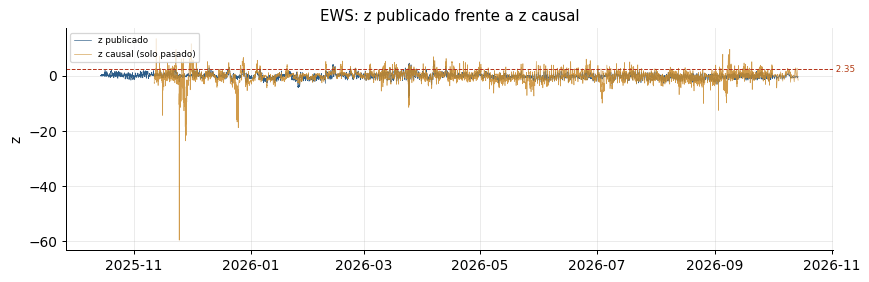

umbral,n_alarmas_publicado,dias_publicado,n_alarmas_causal,dias_causal,n_alarmas_causal_piso,dias_causal_piso
2.35,147,26,740,141,347,79
3.00,44,9,452,99,159,38
4.00,14,4,196,59,51,13
4.70,1,1,107,37,12,3


instantanea_a,instantanea_b,n_comunes,pct_conteo_cambia,pct_esperado_cambia,pct_z_publicado_cambia,max_dif_z_publicado
dashboard_20261006T092320Z.json,dashboard_20261014T103410Z.json,14296,0.00,10.42,2.81,0.04


**Lectura** (cifras calculadas de las tablas):

- 14.335 muestras de 2025-10-14 a 2026-10-14; intervalo más frecuente 30 min (87,0 % de los intervalos).
- Umbral 2,35: 147 alarmas con el z publicado frente a 740 con el z causal (141 días).
- Entre las dos instantáneas cambia el 2,81 % de los z publicados y el 10,42 % de los valores esperados: el archivo se reescribe.

In [36]:
fig, ax = gr.ews_z(EZ)
plt.show()
display(EA.style.hide(axis='index').format(precision=2))
display(EV[['instantanea_a', 'instantanea_b', 'n_comunes', 'pct_conteo_cambia', 'pct_esperado_cambia',
            'pct_z_publicado_cambia', 'max_dif_z_publicado']].style.hide(axis='index').format(precision=2)
        .set_caption('Revisión entre dos instantáneas del archivo'))
moda = EM.loc[EM['n'].idxmax()]
a0 = EA.iloc[0]
lectura(f'{es(len(EZ))} muestras de {EZ["ts"].min()[:10]} a {EZ["ts"].max()[:10]}; intervalo más frecuente '
        f'{es(moda["intervalo_min"])} min ({es(moda["pct"], 1)} % de los intervalos).',
        f'Umbral {es(a0["umbral"], 2)}: {int(a0["n_alarmas_publicado"])} alarmas con el z publicado frente a '
        f'{int(a0["n_alarmas_causal"])} con el z causal ({int(a0["dias_causal"])} días).',
        f'Entre las dos instantáneas cambia el {es(EV["pct_z_publicado_cambia"].iloc[0], 2)} % de los z publicados y el '
        f'{es(EV["pct_esperado_cambia"].iloc[0], 2)} % de los valores esperados: el archivo se reescribe.')

## 13. Redes y fuentes no probadas

De las redes solo se ha medido Truth Social (archivo comunitario de los posts de Donald Trump). Reddit exige OAuth
desde 2023 y su `robots.txt` prohíbe el JSON público; la API de X es de pago; Google Trends no tiene API pública y
reescala cada descarga. AAII y CNN Fear & Greed bloquean la petición: no se esquiva.

Cómo leerlo: posts por día UTC de Truth Social con las crisis de la Fase 1 sombreadas. Los tramos sin línea son
huecos del archivo comunitario (rachas de 7 días o más a 0 posts, que se quitan de la serie): no son días de
silencio. La tabla siguiente lista las fuentes sin datos y su motivo.

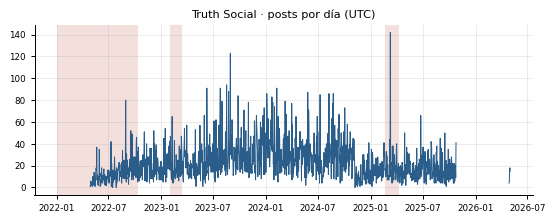

fuente,nombre,familia,estado,motivo,licencia
nyt,"NYT Archive API (titular, abstract y lead paragraph desde 1851)",texto_historico,no_probada,"sin clave (NYT_API_KEY vacía en .env): decisión del usuario, no se registra cuenta; fechas documentadas (no medidas)","NYT APIs Terms of Use: no comercial, atribución, no almacenar más de lo necesar…"
guardian,The Guardian Open Platform (cuerpo completo desde 1999),texto_historico,no_probada,"sin clave (GUARDIAN_API_KEY vacía en .env): decisión del usuario, no se registra cuenta; fechas documentadas (no medidas)",Guardian Open Platform T&C
google_news_rss,Google News RSS (búsqueda; after:/before:),vivo_redes,fallo,robots.txt de news.google.com no permite /rss/search: no se descarga.,Términos de Google
reddit,"Reddit (r/wallstreetbets, r/investing...)",vivo_redes,no_probada,OAuth obligatorio (Data API 2023); robots.txt prohíbe el .json público.,Reddit Data API Terms
x_twitter,X (Twitter) API,vivo_redes,no_probada,"API de pago (0,005 USD por post leído).",X Developer Agreement: prohíbe redistribuir y entrenar modelos
google_trends,Google Trends,vivo_redes,no_probada,Sin API pública; reescala 0-100 en cada descarga (look-ahead si se baja entera).,Términos de Google
aaii_sentiment,"AAII Investor Sentiment Survey (semanal, desde 1987)",indices_ews,fallo,Comprobación educada: robots.txt prohíbe o bloquea (401/403). No se esquiva el bloqueo.,AAII: datos para socios
cnn_fear_greed,CNN Fear & Greed Index,indices_ews,fallo,Comprobación educada: HTTPError: 418 Client Error: Unknown Error for url: https://production.dataviz.cnn.io/index/fearandgreed/graphdata. M…,endpoint interno de CNN sin términos de uso de datos
congreso_senate_efd,Senate eFD (Electronic Financial Disclosures),divulgaciones,no_probada,puerta de aceptación de condiciones por sesión; no se automatiza,puerta de aceptación: 'Prohibition Against Use of Financial Disclosure Reports'
congreso_stock_watcher,"House/Senate Stock Watcher (datasets abiertos, S3)",divulgaciones,fallo,house: HTTPError: 403 Client Error: Forbidden for url: https://house-stock-watcher-data.s3-us-west; senate: HTTPError: 403 Client Error: Fo…,proyecto comunitario


**Lectura** (cifras calculadas de las tablas):

- Truth Social: 29.469 posts de 2022-02-14 a 2026-05-02; media de 23,0 posts/día (p90 43); el archivo lleva 165 días sin actualizarse.
- Huecos del archivo: 2 rachas, 256 días (2022-02-15..2022-04-27 (72 d); 2025-10-26..2026-04-27 (184 d)); fuera de la serie, que no los cuenta como 0 posts.
- 11 fuentes sin datos: **no_probada** 7, **fallo** 4 (nyt, guardian, google_news_rss, reddit, x_twitter, google_trends, aaii_sentiment, cnn_fear_greed, congreso_senate_efd, congreso_stock_watcher, congreso_agregadores_pago).

In [37]:
TR = tabla('truth_resumen')
s_truth = serie('truth_posts_dia')
s_truth = s_truth.reindex(pd.date_range(s_truth.index.min(), s_truth.index.max(), freq='D'))   # hueco = sin línea
fig, axes = gr.paneles_series({'Truth Social · posts por día (UTC)': s_truth}, ncol=1, alto=2.6)
plt.show()
t = TR.iloc[0]
NP = COB[COB['estado'].isin(['no_probada', 'fallo'])].merge(RES[['fuente', 'nombre', 'licencia']], on='fuente')
display(con_estado(NP.assign(motivo=NP['nota'].map(lambda x: corto(x, 140)))
                   [['fuente', 'nombre', 'familia', 'estado', 'motivo', 'licencia']], col='estado'))
lectura(f'Truth Social: {es(t["n_posts"])} posts de {t["inicio"][:10]} a {t["fin"][:10]}; media de '
        f'{es(t["posts_dia_media"], 1)} posts/día (p90 {es(t["posts_dia_p90"])}); el archivo lleva '
        f'{es(t["horas_desde_ultimo"] / 24, 0)} días sin actualizarse.',
        f'Huecos del archivo: {int(t["n_rachas_hueco"])} rachas, {es(t["dias_hueco_archivo"])} días '
        f'({t["rachas_hueco"]}); fuera de la serie, que no los cuenta como 0 posts.',
        f'{len(NP)} fuentes sin datos: ' + ', '.join(f'**{k}** {v}' for k, v in NP['estado'].value_counts().items())
        + ' (' + ', '.join(NP['fuente']) + ').')

## 14. TimeGate: de qué campo sale la fecha y con qué retraso

El TimeGate solo deja ver a un agente lo publicado hasta su fecha de decisión. Cada fuente necesita un campo que
diga **cuándo pudo saberse** el dato, no cuándo ocurrió. La tabla `timegate` guarda ejemplos medidos de fecha del
hecho frente a fecha de publicación con el campo usado; `lag_h` es la diferencia en horas.

In [38]:
tg = TG.assign(lag=pd.to_numeric(TG['lag_h'], errors='coerce'))
CAMPOS = (tg.groupby('fuente')
          .agg(campos=('campo_fecha', lambda s: ' | '.join(corto(x, 60) for x in dict.fromkeys(s.dropna()))),
               ejemplos=('lag', 'size'), con_lag=('lag', 'count'), lag_mediana_h=('lag', 'median'),
               lag_max_h=('lag', 'max'))
          .sort_values('lag_mediana_h'))
display(CAMPOS.style.format(precision=1, na_rep='—').bar(subset=['lag_mediana_h'], color='#e8d3b0', vmin=0))

,campos,ejemplos,con_lag,lag_mediana_h,lag_max_h
fuente,,,,,
truth_social_trump,created_at | created_at -> captura del archivo,6,6,0.0,3948.1
predictit,markets[].timeStamp (hora NY) vs hora de consulta,1,1,0.0,0.0
polymarket,prices-history.t (≤ 16:30 NY) | trades.timestamp (s) vs hora de consulta | gamma endDate -> closedTime (resolución UMA),11,11,0.1,114.5
rss_medios,pubDate -> captura,24,24,0.5,18.4
kalshi,close_time -> settlement_ts (liquidación) | trades.created_time vs hora de consulta,6,6,0.7,0.7
ccnews,article:published_time (≤ WARC-Date) | WARC-Date (rastreo_sin_meta),40,9,0.7,5.5
finra_short_volume,Last-Modified (cabecera HTTP),103,103,1.3,28386.6
gdelt_gkg,DATE (captura); hecho = PAGE_PRECISEPUBTIMESTAMP,6,6,2.5,24.0
bing_news_rss,pubDate -> captura,4,4,13.6,51.5


Cómo leerlo: horas del hecho a la publicación por fuente en escala symlog. Cajas y puntos = ejemplos de `timegate`;
rombos ocres = mediana declarada en `cobertura` para las fuentes sin ejemplos. Las líneas marcan 1 h, 1 día,
1 semana y 45 días. Los valores enormes de CBOE put/call, EWS o Truth no son retrasos de publicación: son ficheros
regenerados o congelados después (la columna `campo_fecha` lo dice) y por eso esas fuentes usan una regla fija.

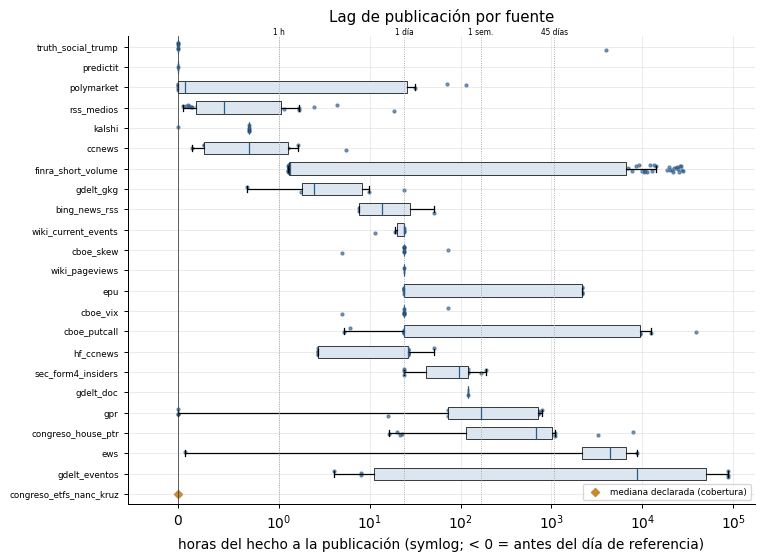

serie,fuente,n_series,referencia_inicio,referencia_fin,lag_mediana_d,lag_max_d,metodo_publicacion
gdelt_tono_economia,gdelt_doc,1,2017-01-01,2026-10-10,5,5,índice DOC con ~4 d de retraso -> D+5; vintage único
wiki_pageviews,wiki_pageviews,6,2015-07-01,2026-10-13,1,1,día UTC cerrado -> D+1
truth_posts_dia,truth_social_trump,1,2022-02-14,2026-05-02,1,1,día UTC cerrado -> D+1
finra_short_ratio_mercado,finra_short_volume,1,2018-08-01,2026-10-01,1,3,"D+1 hábil (fichero ≈18:00 ET, tras el cierre; Last-Modified en disponible_utc)"
congreso_ptr_diarios,congreso_house_ptr,1,2014-01-02,2026-10-12,1,3,"FilingDate + 1 días hábiles (k = p90 medido, n=42)"
congreso_etf_nanc_kruz,congreso_etfs_nanc_kruz,1,2023-02-07,2026-10-13,0,0,cierre diario (Yahoo vía yfinance)
polymarket_recesion_eeuu_2025,polymarket,1,2025-01-08,2025-12-31,0,0,tiempo real; último punto CLOB ≤ 16:30 NY del día (resolución 12 h)
polymarket_fed_recorte25_sep2025,polymarket,1,2025-05-08,2025-09-17,0,0,tiempo real; último punto CLOB ≤ 16:30 NY del día (resolución 12 h)
polymarket_recesion_eeuu_2026,polymarket,1,2025-09-30,2026-10-14,0,0,tiempo real; último punto CLOB ≤ 16:30 NY del día (resolución 12 h)
polymarket_recesion_eeuu_2024,polymarket,1,2024-08-05,2024-12-31,0,0,tiempo real; último punto CLOB ≤ 16:30 NY del día (resolución 12 h)


**Lectura** (cifras calculadas de las tablas):

- 332 ejemplos de TimeGate en 23 fuentes; 0 con lag negativo.
- 18 de 23 series se publican en D+1 o antes (mediana).
- Series con lag mediano de una semana o más: `gpr_mensual` 31 d, `epu_global_mensual` 91 d, `ews_z_publicado` 216 d.
- 4 series guardadas con el vintage actual revisable (fecha correcta, valor quizá revisado).

In [39]:
fig, ax = gr.lags_publicacion(TG, COB)
plt.show()
display(SER[['serie', 'fuente', 'n_series', 'referencia_inicio', 'referencia_fin', 'lag_mediana_d', 'lag_max_d',
             'metodo_publicacion']].style.hide(axis='index').format(precision=0)
        .bar(subset=['lag_mediana_d'], color='#c9d9ea', vmin=0)
        .set_caption('Series del corpus: lag fecha_referencia → fecha_publicacion (días)'))
neg = int((tg['lag'] < 0).sum())
lentas = SER[SER['lag_mediana_d'] >= 7]
lectura(f'{es(len(TG))} ejemplos de TimeGate en {TG["fuente"].nunique()} fuentes; {neg} con lag negativo.',
        f'{int((SER["lag_mediana_d"] <= 1).sum())} de {len(SER)} series se publican en D+1 o antes (mediana).',
        'Series con lag mediano de una semana o más: ' + ', '.join(f'`{r.serie}` {int(r.lag_mediana_d)} d'
                                                             for r in lentas.itertuples()) + '.',
        f'{int((SER["metodo_publicacion"] == base.REVISABLE).sum())} series guardadas con el vintage actual revisable '
        '(fecha correcta, valor quizá revisado).')

## 15. Volumen y coste

`volumen.csv` separa lo medido (ítems y MB de la muestra) de la extrapolación al corpus completo
(`gb_corpus_estimado`, a partir de la cifra de la ficha o de su tasa por la cobertura). Las horas de descarga usan
la velocidad medida con la caché caliente, dominada por la latencia de peticiones pequeñas: son una **cota
pesimista** y solo valen como orden de magnitud.

Cómo leerlo: escala logarítmica. A la izquierda, los GB extrapolados del corpus completo de cada fuente; a la
derecha, los MB realmente descargados en la sonda. Las fuentes sin barra no tienen cifra (la ficha no da volumen o
no se descargó nada).

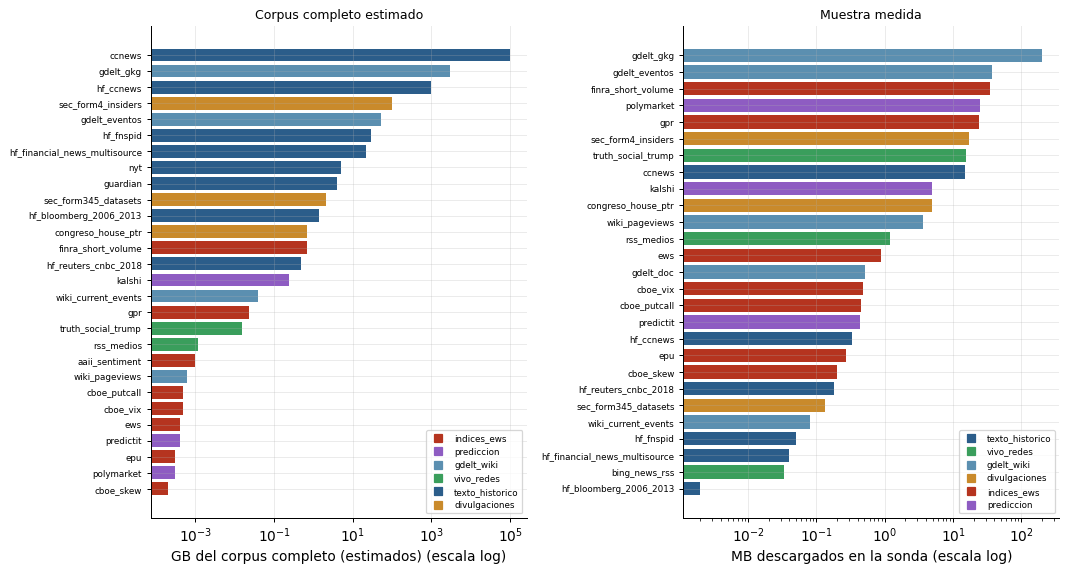

In [40]:
V = VOL.merge(COB[['fuente', 'familia']], on='fuente', how='left')
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
gr.volumen_fuentes(V, col_valor='gb_corpus_estimado', unidad='GB del corpus completo (estimados)', ax=axes[0])
axes[0].set_title('Corpus completo estimado', fontsize=10)
gr.volumen_fuentes(V, col_valor='mb_muestra', unidad='MB descargados en la sonda', ax=axes[1])
axes[1].set_title('Muestra medida', fontsize=10)
fig.tight_layout()
plt.show()

In [41]:
FICHAS = pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in sorted((R / 'fichas').glob('*.json'))])
VV = V.merge(FICHAS[['fuente', 'acceso', 'autenticacion', 'coste']], on='fuente', how='left')
display(VV.sort_values('gb_corpus_estimado', ascending=False)
        [['fuente', 'familia', 'n_items_muestra', 'mb_muestra', 'gb_corpus_estimado', 'horas_descarga_estimadas',
          'acceso', 'autenticacion', 'coste']].style.hide(axis='index')
        .format({'mb_muestra': '{:.1f}', 'gb_corpus_estimado': '{:,.2f}', 'horas_descarga_estimadas': '{:,.1f}',
                 'n_items_muestra': '{:,.0f}'}, na_rep='—')
        .background_gradient(subset=['gb_corpus_estimado'], cmap='Oranges'))
gb = VV['gb_corpus_estimado'].dropna().sort_values(ascending=False)
gratis = VV['coste'].astype(str).str.startswith('0')
lectura(f'Muestra de la sonda: {es(VV["mb_muestra"].sum(), 0)} MB y {es(VV["n_items_muestra"].sum())} ítems.',
        f'Corpus completo estimado: {es(gb.sum() / 1e3, 1)} TB; `{VV.loc[gb.index[0], "fuente"]}` aporta el '
        f'{es(100 * gb.iloc[0] / gb.sum(), 1)} % y las tres mayores ({", ".join(VV.loc[gb.index[:3], "fuente"])}) el '
        f'{es(100 * gb.iloc[:3].sum() / gb.sum(), 1)} %.',
        f'Sin cifra de volumen: {int(VV["gb_corpus_estimado"].isna().sum())} fuentes.',
        f'Velocidad medida: mediana {es(VV["mb_s_medidos"].median(), 3)} MB/s (cota pesimista de las horas).',
        f'Coste: {int(gratis.sum())} de {len(VV)} fuentes a 0 €; el resto: '
        + ', '.join(f'`{r.fuente}` ({corto(r.coste, 40)})' for r in VV[~gratis].itertuples()) + '.')

fuente,familia,n_items_muestra,mb_muestra,gb_corpus_estimado,horas_descarga_estimadas,acceso,autenticacion,coste
ccnews,texto_historico,350,15.0,"97,169.49","64,110.1",descarga,ninguna,0 €
gdelt_gkg,gdelt_wiki,"30,553",201.7,"2,900.00",371.5,descarga,ninguna,0 €
hf_ccnews,texto_historico,4,0.3,966.82,637.9,descarga,ninguna,0 €
sec_form4_insiders,divulgaciones,322,17.3,102.00,67.3,descarga,ninguna,0 €
gdelt_eventos,gdelt_wiki,31,36.6,53.60,35.4,descarga,ninguna,0 €
hf_fnspid,texto_historico,3,0.1,29.55,19.5,descarga,ninguna,0 €
hf_financial_news_multisource,texto_historico,1,0.0,21.41,14.1,descarga,cuenta HF + aceptar condiciones,0 €
nyt,texto_historico,0,0.0,5.00,3.3,api,clave gratuita,0 €
guardian,texto_historico,0,0.0,4.00,2.6,api,clave gratuita,0 €
sec_form345_datasets,divulgaciones,1,0.1,2.07,3.9,descarga,ninguna,0 €


**Lectura** (cifras calculadas de las tablas):

- Muestra de la sonda: 388 MB y 251.525 ítems.
- Corpus completo estimado: 101,3 TB; `ccnews` aporta el 96,0 % y las tres mayores (ccnews, gdelt_gkg, hf_ccnews) el 99,8 %.
- Sin cifra de volumen: 11 fuentes.
- Velocidad medida: mediana 0,421 MB/s (cota pesimista de las horas).
- Coste: 37 de 39 fuentes a 0 €; el resto: `x_twitter` (pago por uso: 0,005 USD por post leído …), `congreso_agregadores_pago` (Quiver API desde ≈30 USD/mes; Unusual W…).

## 16. Fichas de fuente

Cada fuente deja una `FichaFuente` (contrato común de la Fase 2, `ingesta.comun.esquema`) en
`results/ingesta/noticias_alt/fichas/<fuente>.json`: acceso, autenticación, coste, licencia, cobertura, frecuencia,
retraso, formato, límites, estado y mediciones. La tabla las resume; la figura cuenta, para cada agente del sistema,
cuántas fuentes le sirven y en qué estado están.

Cómo leerlo: barras apiladas por estado de la sonda (verde ok, ámbar parcial, rojo fallo, gris no probada). Una
fuente se cuenta una vez en cada agente al que sirve, así que la suma de las barras supera el número de fichas.

fuente,nombre,rag,acceso,autenticacion,frecuencia,formato,limites,estado_sonda
aaii_sentiment,"AAII Investor Sentiment Survey (semanal, desde 1987)",serie,descarga,socio (descarga),semanal (jueves),xls,403 al robot (protección anti-bot / socios),fallo
bing_news_rss,Bing News RSS (búsqueda en vivo),cajon,api,ninguna,minutos,"rss (título, extracto, enlace apiclick, News:Source)",sin clave; sin histórico ni filtro de fechas; no docum…,ok
cboe_putcall,"CBOE ratios put/call (total, equity, index)",serie,descarga,ninguna,diaria (hábiles),csv (hasta 2019) + json diario,"CSV históricos congelados; después, un JSON por día (≈…",parcial
cboe_skew,CBOE SKEW Index,serie,descarga,ninguna,diaria (hábiles),csv,sin clave,ok
cboe_vix,CBOE VIX (histórico diario),serie,descarga,ninguna,diaria (hábiles),csv,sin clave,ok
ccnews,"Common Crawl CC-NEWS (WARC, texto completo, mundial)",cajon,descarga,ninguna,continua (un WARC cada pocas horas),warc.gz (HTTP crudo con HTML),sin clave; HTTP con Range sobre data.commoncrawl.org; …,ok
cnn_fear_greed,CNN Fear & Greed Index,serie,api,ninguna,diaria,json,anti-bot (418 «You're a bot») sin cabeceras de navegad…,fallo
congreso_agregadores_pago,Quiver Quantitative · Capitol Trades · Unusual Whales,ninguno,api,pago,diaria,json/csv,según plan,no_probada
congreso_etfs_nanc_kruz,ETFs NANC y KRUZ (réplica de carteras del Congreso),serie,libreria,ninguna,diaria,dataframe (yfinance),yfinance no oficial,parcial
congreso_house_ptr,House Clerk · Periodic Transaction Reports (STOCK Act),serie,descarga,ninguna,por evento (≈646 PTR/año),zip (xml/txt índice) + pdf por PTR (texto si electróni…,sin clave; 1 petición/s; los PTR escaneados (DocID 8/9…,ok


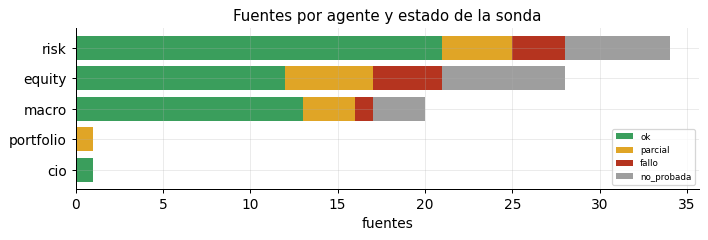

modulo,jsonl,n_documentos
ccnews,ccnews_muestra,350
gdelt,gdelt_gkg_titulares,30553
gdelt,gdelt_doc_titulares,657
wikipedia,wiki_current_events,71
rss,rss_titulares,983
rss,bing_news_titulares,35
social,truth_posts_testigo,48


**Lectura** (cifras calculadas de las tablas):

- 39 fichas; campo `rag` de la ficha: **serie** 18, **cajon** 16, **ninguno** 4, **base** 1.
- Fuentes por agente: `risk` 34, `equity` 28, `macro` 20, `cio` 1, `portfolio` 1.
- Corpus de la pasada completa: 32.697 documentos en 7 jsonl y 23 parquet de series; 43,1 MB en total.

In [42]:
cols = ['fuente', 'nombre', 'rag', 'acceso', 'autenticacion', 'frecuencia', 'formato', 'limites', 'estado_sonda']
FT = FICHAS[cols].copy()
for c in ('nombre', 'autenticacion', 'frecuencia', 'formato', 'limites'):
    FT[c] = FT[c].map(lambda x: corto(x, 55))
display(con_estado(FT))
AG = FICHAS.assign(agente=FICHAS['agentes']).explode('agente').groupby(['agente', 'estado_sonda']).size().unstack(fill_value=0)
AG = AG.reindex(columns=[e for e in gr.C_ESTADO if e in AG.columns]).loc[lambda d: d.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 2.8))
izq = np.zeros(len(AG))
for e in AG.columns:
    ax.barh(AG.index, AG[e], left=izq, color=gr.C_ESTADO[e], label=e)
    izq += AG[e].to_numpy()
ax.set_xlabel('fuentes')
ax.legend(fontsize=7, loc='lower right')
ax.set_title('Fuentes por agente y estado de la sonda')
plt.tight_layout()
plt.show()
ficheros = [p for sub in ('documentos', 'series') for p in (corpus_dir('noticias_alt') / sub).glob('*.*')
            if '_rapido' not in p.stem]
CORP = pd.DataFrame([dict(carpeta=p.parent.name, fichero=p.name, mb=p.stat().st_size / 1e6) for p in ficheros])
display(DOC.style.hide(axis='index').set_caption('Documentos guardados en el corpus (jsonl)'))
lectura(f'{len(FICHAS)} fichas; campo `rag` de la ficha: ' + ', '.join(f'**{k}** {v}' for k, v in FICHAS['rag'].value_counts().items()) + '.',
        'Fuentes por agente: ' + ', '.join(f'`{a}` {int(n)}' for a, n in AG.sum(axis=1).sort_values(ascending=False).items()) + '.',
        f'Corpus de la pasada completa: {es(DOC["n_documentos"].sum())} documentos en {len(DOC)} jsonl y '
        f'{int((CORP["carpeta"] == "series").sum())} parquet de series; {es(CORP["mb"].sum(), 1)} MB en total.')

## 17. Resumen para la reunión

In [43]:
e = RES['estado_sonda'].value_counts()
apto = COB[PROBADA & COB['backtest'].astype(bool)]
print('SONDA DEL TEMA 4 · NOTICIAS Y DATOS ALTERNATIVOS')
print(f'- {len(RES)} fuentes en {len(MOD)} módulos: ' + ', '.join(f'{k} {v}' for k, v in e.items()) + '.')
print(f'- {es(len(REG))} peticiones ({es(n_cache)} de caché, {int((~REG["ok"].astype(bool)).sum())} fallidas); '
      f'{es(MOD["segundos"].sum())} s de ejecución.')
print(f'- Probadas y aptas para backtest por cobertura: {len(apto)} '
      f'({", ".join(apto.sort_values("inicio_dt")["fuente"].head(8))}…).')
print(f'- Texto completo: antes de 2000 solo {", ".join(txt["1979-1999"]) or "nada"}; '
      f'2007-2015 {len(txt["2007-2015"])} fuentes; desde {COB.set_index("fuente").loc["ccnews", "inicio"][:7]} CC-NEWS (≈{es(ok_cc["gb_mes_est"].max())} GB/mes en el mes más cargado).')
print(f'- Destinos: ' + ', '.join(f'{k} {v}' for k, v in COB['destino'].fillna('ninguno').value_counts().items()) + '.')
print(f'- TimeGate: {len(TG)} ejemplos, {neg} con lag negativo; {int((SER["lag_mediana_d"] <= 1).sum())}/{len(SER)} '
      f'series en D+1 o antes; Congreso: mediana {es(OPS["lag_dias"].median())} d de operación a publicación '
      f'({es(100 * (pd.to_numeric(OPS["lag_dias"], errors="coerce") > 45).mean(), 1)} % fuera de plazo).')
print(f'- Limpieza: tras el embudo queda entre {es(fin_e["pct_restante"].min(), 1)} % y {es(fin_e["pct_restante"].max(), 1)} % '
      f'por día; {len(SIN)} grupos sindicados (máx. {int(SIN["n_medios"].max())} medios).')
print(f'- Wikipedia Current Events: la versión actual tiene un {es(anadido, 1)} % más de hechos que al cierre del día; '
      f'página diaria contemporánea solo desde {primer}.')
print(f'- EWS: {int(a0["n_alarmas_publicado"])} alarmas con el z publicado frente a {int(a0["n_alarmas_causal"])} '
      f'con el causal (umbral {es(a0["umbral"], 2)}): solo en vivo.')
print(f'- Mercados de predicción: días testigo con mercados activos desde el {primera_liq:%Y-%m-%d}; {len(SAL)} saltos ≥ 15 pp en {EMBL["serie"].nunique()} mercados.')
print(f'- Volumen estimado del corpus completo: {es(gb.sum() / 1e3, 1)} TB ({es(100 * gb.iloc[0] / gb.sum())} % '
      f'{VV.loc[gb.index[0], "fuente"]}); horas de descarga = cota pesimista.')
print(f'- Sin datos ({len(NP)}): ' + ', '.join(NP['fuente']) + '.')
print('- Pendiente: claves de NYT/Guardian (decisión del usuario), validez de señales en t4_02.')

SONDA DEL TEMA 4 · NOTICIAS Y DATOS ALTERNATIVOS
- 39 fuentes en 12 módulos: ok 22, no_probada 7, parcial 6, fallo 4.
- 1.025 peticiones (528 de caché, 40 fallidas); 278 s de ejecución.
- Probadas y aptas para backtest por cobertura: 23 (gpr, gdelt_eventos, epu, hf_financial_news_multisource, cboe_skew, cboe_vix, hf_fnspid, sec_form345_datasets…).
- Texto completo: antes de 2000 solo hf_fnspid, hf_financial_news_multisource; 2007-2015 4 fuentes; desde 2016-08 CC-NEWS (≈799 GB/mes en el mes más cargado).
- Destinos: serie 14, cajon 11, ninguno 9, vivo 4, base 1.
- TimeGate: 332 ejemplos, 0 con lag negativo; 18/23 series en D+1 o antes; Congreso: mediana 41 d de operación a publicación (38,6 % fuera de plazo).
- Limpieza: tras el embudo queda entre 90,1 % y 100,0 % por día; 67 grupos sindicados (máx. 10 medios).
- Wikipedia Current Events: la versión actual tiene un 29,7 % más de hechos que al cierre del día; página diaria contemporánea solo desde 2006-12-01.
- EWS: 147 alarmas con el z 